# Assignment 2: Risk Modeling and Event Classification

## NAIF BAYES CLASSIFIER TEAM

### Akhmad Fauzi Nurulhamzah
### [teammate]
### [teammate]

# **PART A. Modeling Car Accident Risks and Outcomes With Bayesian Networks**

In [3]:
# Import pgmpy and print its version
!pip install pgmpy
import pgmpy

print("pgmpy version:", pgmpy.__version__)

pgmpy version: 1.0.0


In [4]:
!python.exe -m pip install --upgrade pip
!pip install sklearn-crfsuite

In [5]:
# Library
# Enable inline plotting in Jupyter
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.readwrite import BIFReader
from pgmpy.inference import VariableElimination
import numpy as np
import matplotlib.patches as mpatches
from pgmpy.models import BayesianNetwork
from pgmpy.factors.discrete import TabularCPD

## Task 1A. modify the Conditional Probability Distributions (CPDs)

### Introduction

**Modeling Car Accident Risks with Bayesian Networks**

This assignment utilizes *insurance.bif* dataset to model the relationships of car accident risks through a Bayesian network; the graphical network model maps the conditional dependencies between **car accidents, vehicle characteristics, driver behavior, and associated costs**. By structuring these elements as interconnected nodes, the model provides a clear visualization of how a single shift in driver quality or vehicle age can cascade into significant changes in accident severity and financial liability.

The primary objective of the task is to perform a sensitivity analysis by modifying the conditional probability distributions (CPDs) within the network by adjusting the underlying probabilities of specific nodes to reflect varying real-world scenarios. Furthermore, we will analyze how these changes propagate through the network and affect the probabilities of related nodes, then provide practical insights and recommendations.


### Model Structure & Visualization

The insurance.bif model is a Directed Acyclic Graph (DAG) consisting of 27 nodes. It represents a causal chain where socioeconomic factors and age influence driver traits, which in turn dictate the likelihood of accidents and subsequent financial liabilities.

#### Bayesian Network Architecture

In [10]:
#Load the Insurance BIF file
bif_reader = BIFReader("insurance.bif")

model = bif_reader.get_model()

#Inspect the model
print("Nodes in the model:")
print(list(model.nodes()))

print("\nEdges in the model:")
print(list(model.edges()))

print("\nCPDs in the model:")
for cpd in model.get_cpds():
    print("\nCPD for:", cpd.variable)
    print(cpd)


Nodes in the model:
['GoodStudent', 'Age', 'SocioEcon', 'RiskAversion', 'VehicleYear', 'ThisCarDam', 'RuggedAuto', 'Accident', 'MakeModel', 'DrivQuality', 'Mileage', 'Antilock', 'DrivingSkill', 'SeniorTrain', 'ThisCarCost', 'Theft', 'CarValue', 'HomeBase', 'AntiTheft', 'PropCost', 'OtherCarCost', 'OtherCar', 'MedCost', 'Cushioning', 'Airbag', 'ILiCost', 'DrivHist']

Edges in the model:
[('Age', 'GoodStudent'), ('Age', 'SocioEcon'), ('Age', 'RiskAversion'), ('Age', 'DrivingSkill'), ('Age', 'SeniorTrain'), ('Age', 'MedCost'), ('SocioEcon', 'GoodStudent'), ('SocioEcon', 'RiskAversion'), ('SocioEcon', 'VehicleYear'), ('SocioEcon', 'MakeModel'), ('SocioEcon', 'HomeBase'), ('SocioEcon', 'AntiTheft'), ('SocioEcon', 'OtherCar'), ('RiskAversion', 'VehicleYear'), ('RiskAversion', 'MakeModel'), ('RiskAversion', 'DrivQuality'), ('RiskAversion', 'SeniorTrain'), ('RiskAversion', 'HomeBase'), ('RiskAversion', 'AntiTheft'), ('RiskAversion', 'DrivHist'), ('VehicleYear', 'RuggedAuto'), ('VehicleYear', '

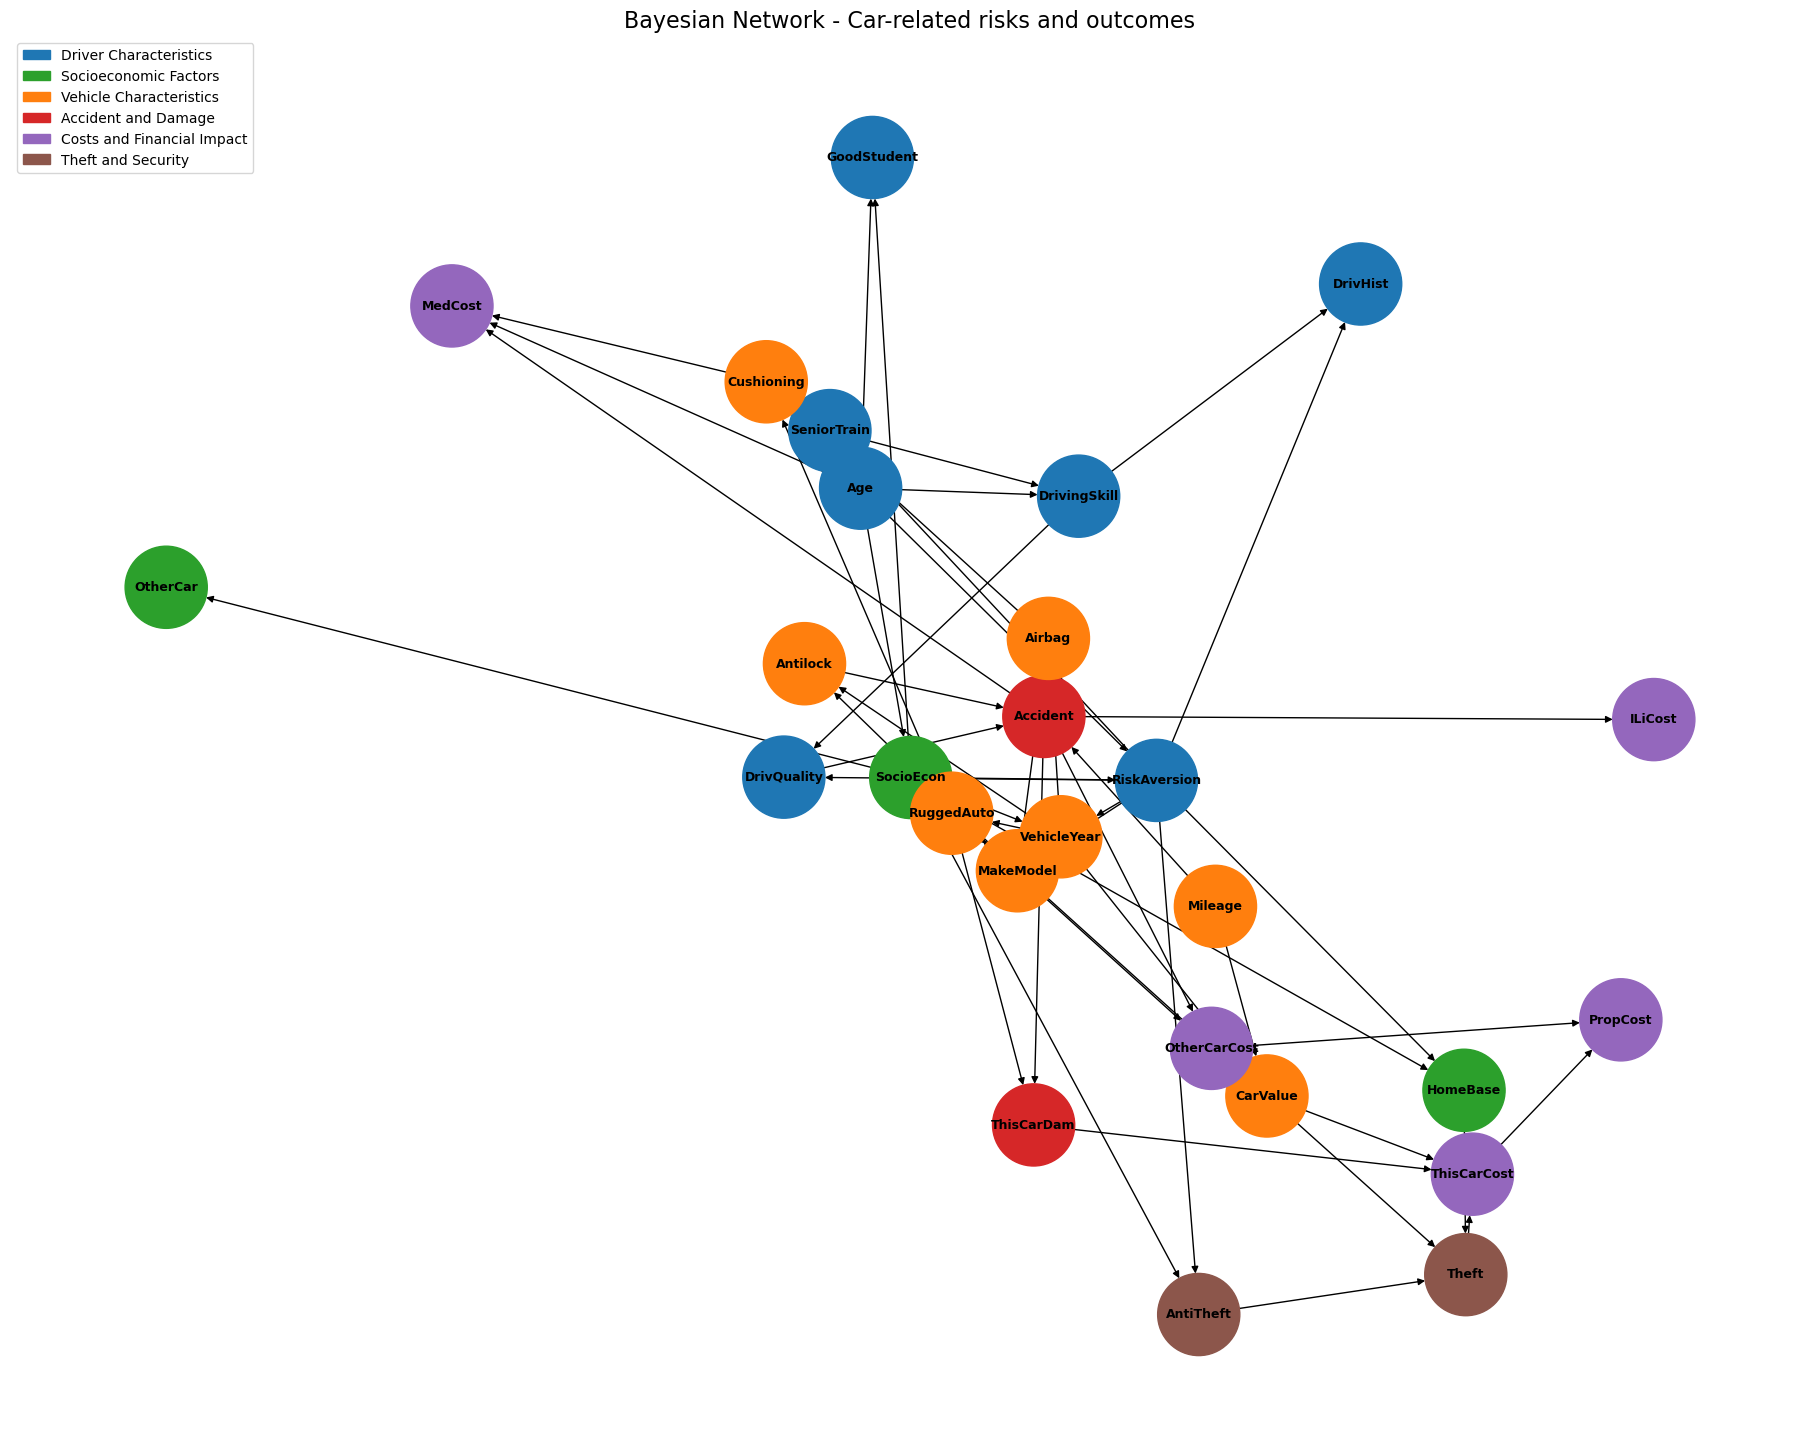

In [11]:
# Create directed graph from Bayesian model
G = nx.DiGraph()
G.add_nodes_from(model.nodes())
G.add_edges_from(model.edges())

# Define node groups based on conceptual categories

# Driver-related attributes
driver_nodes = [
    "Age", "GoodStudent", "RiskAversion",
    "DrivingSkill", "DrivQuality",
    "DrivHist", "SeniorTrain"
]

# Socioeconomic and environment factors
socio_nodes = [
    "SocioEcon", "HomeBase", "OtherCar"
]

# Vehicle characteristics and safety features
vehicle_nodes = [
    "VehicleYear", "MakeModel", "RuggedAuto",
    "Antilock", "Airbag", "Cushioning",
    "Mileage", "CarValue"
]

# Accident and damage outcomes
accident_nodes = [
    "Accident", "ThisCarDam"
]

# Financial cost variables
cost_nodes = [
    "ThisCarCost", "OtherCarCost",
    "MedCost", "ILiCost", "PropCost"
]

# Theft and security related variables
theft_nodes = [
    "Theft", "AntiTheft"
]

# Define color mapping for each group
color_dict = {
    "Driver": "#1f77b4",
    "Socioeconomic": "#2ca02c",
    "Vehicle": "#ff7f0e",
    "Accident/Damage": "#d62728",
    "Costs": "#9467bd",
    "Theft/Security": "#8c564b"
}

# Assign a color to each node depending on its group
color_map = []

for node in G.nodes():
    if node in driver_nodes:
        color_map.append(color_dict["Driver"])
    elif node in socio_nodes:
        color_map.append(color_dict["Socioeconomic"])
    elif node in vehicle_nodes:
        color_map.append(color_dict["Vehicle"])
    elif node in accident_nodes:
        color_map.append(color_dict["Accident/Damage"])
    elif node in cost_nodes:
        color_map.append(color_dict["Costs"])
    elif node in theft_nodes:
        color_map.append(color_dict["Theft/Security"])
    else:
        color_map.append("gray")  # fallback color if node not categorized

# Generate graph layout using spring algorithm
pos = nx.spring_layout(G, k=1.5, iterations=200, seed=42)

# Create figure with larger size for readability
plt.figure(figsize=(18, 14))

# Draw the network graph
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3500,
    node_color=color_map,
    font_size=9,
    font_weight="bold",
    arrows=True,
)

# Create legend entries corresponding to each group
legend_patches = [
    mpatches.Patch(color=color_dict["Driver"], label="Driver Characteristics"),
    mpatches.Patch(color=color_dict["Socioeconomic"], label="Socioeconomic Factors"),
    mpatches.Patch(color=color_dict["Vehicle"], label="Vehicle Characteristics"),
    mpatches.Patch(color=color_dict["Accident/Damage"], label="Accident and Damage"),
    mpatches.Patch(color=color_dict["Costs"], label="Costs and Financial Impact"),
    mpatches.Patch(color=color_dict["Theft/Security"], label="Theft and Security"),
]

# Add legend to plot
plt.legend(handles=legend_patches, loc="upper left", fontsize=10)

# Add title and display graph
plt.title("Bayesian Network - Car-related risks and outcomes", fontsize=16)
plt.show()


#### The CPD tables (Data Probabilities)

In [13]:
# Load the Bayesian Network from the BIF file
bif_reader = BIFReader(r"insurance.bif")  # Replace with your actual file path
model = bif_reader.get_model()

# Print all CPDs in the model
for cpd in model.get_cpds():
    print(f"CPD for {cpd.variable}:\n")
    print(cpd)
    print("\n" + "="*50 + "\n")

CPD for Accident:

+--------------------+-------------------+-----+---------------------+------------------------+
| Antilock           | Antilock(True)    | ... | Antilock(False)     | Antilock(False)        |
+--------------------+-------------------+-----+---------------------+------------------------+
| Mileage            | Mileage(FiveThou) | ... | Mileage(Domino)     | Mileage(Domino)        |
+--------------------+-------------------+-----+---------------------+------------------------+
| DrivQuality        | DrivQuality(Poor) | ... | DrivQuality(Normal) | DrivQuality(Excellent) |
+--------------------+-------------------+-----+---------------------+------------------------+
| Accident(None)     | 0.7               | ... | 0.94                | 0.98                   |
+--------------------+-------------------+-----+---------------------+------------------------+
| Accident(Mild)     | 0.2               | ... | 0.03                | 0.01                   |
+--------------------

**1. Driver Demographics & Socio-Economics**

CPD for Age
| Age Group | Probability |
| :--- | :--- |
| Adolescent | 0.2 (20%) |
| Adult | 0.6 (60%) |
| Senior | 0.2 (20%) |

Insight: This table shows the base makeup of the population. It indicates that the vast majority of drivers in this model are Adults, making up 60% of the group. Adolescents and Seniors are equally represented as smaller minorities at 20% each. This is the starting point for all other calculations.

CPD for SocioEcon (Socio-Economic Status)
| Status | Adolescent | Adult | Senior |
| :--- | :--- | :--- | :--- |
| Prole | 0.4 | 0.4 | 0.5 |
| Middle | 0.4 | 0.4 | 0.2 |
| UpperMiddle | 0.19 | 0.19 | 0.29 |
| Wealthy | 0.01 | 0.01 | 0.01 |

Insight: This table reveals how age influences wealth. It shows that as people get older, their economic status shifts; for instance, half of the Senior population is classified as Prole, while the Wealthy status is extremely rare across all age groups, holding steady at only 1%. This tells the model that most drivers are in the lower-to-middle economic brackets.

**2. Driver Behavior & Skill**

CPD for RiskAversion
| State | Probability (for Wealthy Senior) |
| :--- | :--- |
| Psychopath | 0.01 (1%) |
| Adventurous | 0.09 (9%) |
| Normal | 0.40 (40%) |
| Cautious | 0.50 (50%) |

Insight: This result shows the behavior of a Wealthy Senior. In this model, these individuals are highly prone to safety, with a 90% combined probability of being either Cautious or Normal. This reflects a logic where older, wealthier drivers tend to protect their assets and health by avoiding risky behavior.

CPD for DrivingSkill
| State | Probability (for Senior with No Training) |
| :--- | :--- |
| SubStandard | 0.4 (40%) |
| Normal | 0.5 (50%) |
| Expert | 0.1 (10%) |

Insight: This focuses on Seniors who have not undergone Senior Training. Without that specific education, the model assumes a significant risk: there is a 40% chance their skills are Substandard and only a 10% chance of being an Expert. This highlights the model's belief that age alone does not guarantee skill.

CPD for DrivQuality
| Quality | Probability (for Cautious Expert) |
| :--- | :--- |
| Poor | 0.0 (0%) |
| Normal | 0.0 (0%) |
| Excellent | 1.0 (100%) |

Insight: This represents a perfect logical link. It shows that when a driver is both an Expert and Cautious, the quality of their driving is guaranteed to be Excellent with 100% certainty. It removes all randomness when these two high-quality traits overlap.

**3. Vehicle Technology & Value**

CPD for CarValue
| Value Level | Probability (Older SuperLuxury with High Mileage) |
| :--- | :--- |
| FiveThou to FiftyThou | ~0.000001 |
| Million | 0.999996 (~100%) |

Insight: This table shows a strong assumption about high-end vehicles. For a Super Luxury car that is Older and has high mileage (Domino), the model still assigns a near-100% probability that its value remains in the Million dollar bracket. This implies the model is dealing with collector-grade vehicles that do not depreciate normally.

CPD for Airbag / Antilock
| Feature | Probability (Older SuperLuxury) |
| :--- | :--- |
| True (Equipped) | 0.10 (Airbag) / 0.15 (Antilock) |
| False (Missing) | 0.90 (Airbag) / 0.85 (Antilock) |

Insight: These results demonstrate the technological gap in older vehicles. Even for a Super Luxury model, if the car is Older, the chance of it having an Airbag is only 10%. This informs the model that vehicle age is a higher risk factor for safety than the original price of the car.

**4. Incident & Accident Likelihood**

CPD for Accident
| Severity | Prob (Excellent Driver, No Antilock, High Mileage) |
| :--- | :--- |
| None | 0.98 (98%) |
| Mild | 0.01 (1%) |
| Moderate | 0.007 (0.7%) |
| Severe | 0.003 (0.3%) |

Insight: This is a critical insight into human vs. machine safety. Even with No Antilock brakes and very high mileage, an Excellent driver has a 98% chance of having no accident. This tells us the model weights high driving quality much more heavily than the presence of safety technology.

CPD for Theft
| Theft State | Prob (Secure HomeBase, AntiTheft True, Million Value) |
| :--- | :--- |
| True | 0.000001 (~0%) |
| False | 0.999999 (~100%) |

Insight: This table shows how security features and location act as a shield. If a car has an Anti-Theft system and is kept in a Secure Home Base, the chance of it being stolen is practically zero, even if the car is worth a Million dollars. Security and environment outweigh the "temptation" of the car's high value.

**5. Damage & Financial Consequences**

CPD for ThisCarDam (Physical Damage)
| Damage Level | Probability (Severe Accident, Tank-like Car) |
| :--- | :--- |
| None | 0.05 (5%) |
| Mild / Moderate | 0.20 each (40% total) |
| Severe | 0.55 (55%) |

Insight: This result looks at what happens when a very sturdy car (Tank) gets into a Severe Accident. Even with the highest level of ruggedness, the car still has a 55% chance of suffering Severe damage, indicating that high-intensity crashes generally overcome even the best vehicle armor.

CPD for ThisCarCost (Financial Cost)
| Claim Amount | Prob (Severe Damage, Million Value, No Theft) |
| :--- | :--- |
| Thousand to TenThou | ~0.000001 |
| HundredThou | 0.029 (2.9%) |
| Million | 0.97 (97%) |

Insight: This table links physical damage directly to money. If a Million dollar car has suffered Severe damage, there is a 97% probability that the cost to the insurance company will be a Million dollars. This represents a "total loss" scenario where the repair cost effectively equals the total value of the vehicle.

CPD for PropCost (Total Property Cost)
| Total Cost | Prob (ThisCar: Million, OtherCar: Million) |
| :--- | :--- |
| Million | 1.0 (100%) |
| All other states | 0.0 (0%) |

Insight: This final table represents a simplified mathematical rule for total liability. It shows that if the cost for the user's car is a Million and the cost for the other car involved is also a Million, the total property cost is 100% guaranteed to be a Million. This acts as a maximum cap for total property claims in this specific model pathway.

### Scenario-Based CPD Adjustments

#### Relevant Nodes to Adjust for CPD and Its Observed Effects

| Adjusted Node | Observed Effect on (Child Nodes) |
|---------------|----------------------------------|
| RiskAversion  | DrivQuality, MakeModel, AntiTheft, HomeBase |
| DrivQuality   | Accident |
| DrivingSkill  | DrivQuality, DrivHist |
| Accident      | ILiCost, MedCost, OtherCarCost, ThisCarDam |
| CarValue      | Theft, ThisCarCost |
| Theft         | ThisCarCost |
| SocioEcon     | RiskAversion, MakeModel, OtherCar, VehicleYear |
| ThisCarDam    | ThisCarCost |

#### 1. Severe Accidents Are More Likely Scenario

**Scenario Description and Assumption**

This scenario reflects a deterioration in road safety conditions where severe car accidents become more frequent. Possible real-world causes include:

- Poor infrastructure conditions
- Increased traffic density
- Reduced enforcement of traffic regulations
- Higher levels of distracted or reckless driving

To model this scenario, the CPD of the accident node was modified to increase the probability of severe accidents from 0.003 to 0.2. This represents a substantial increase in high-severity crash likelihood.


**Relevant Nodes to Adjust for CPD and Its Observed Effects**

| Adjusted Node | Observed Effect on (Child Nodes) |
|---------------|----------------------------------|
| Accident      | MedCost, ThisCarCost, ILiCost, OtherCarCost Costs?stribution?

**Research Questions**

- RQ1: How does an increase in Severe Accidents change the predicted Medical Costs?
- RQ2 How does having more Severe Accidents lead to higher Car Repair Costs?


**a. Modification of the Accident CPD**

This code modifies the prior probability distribution of the Accident node to simulate a scenario in which severe accidents become more frequent. In the original model, accidents were overwhelmingly unlikely,

In [20]:
# Accident CPD

def modify_accident_cpd():

    accident_states = ['None', 'Mild', 'Moderate', 'Severe']

    # Original baseline (from insurance.bif structure)
    original_probs = {
        'None': 0.98,
        'Mild': 0.01,
        'Moderate': 0.007,
        'Severe': 0.003
    }

    # Modified scenario: severe accidents significantly more likely (20%)
    modified_probs = {
        'None': 0.65,
        'Mild': 0.05,
        'Moderate': 0.10,
        'Severe': 0.20
    }

    # Ensure probabilities sum to 1
    assert abs(sum(modified_probs.values()) - 1.0) < 1e-10

    print("Accident CPD Modification\n")
    print("{:<10} {:<10} {:<10} {:<10}".format(
        "Severity", "Original", "Modified", "Difference"
    ))
    print("-" * 45)

    for state in accident_states:
        diff = modified_probs[state] - original_probs[state]
        print("{:<10} {:<10.3f} {:<10.3f} {:+<10.3f}".format(
            state,
            original_probs[state],
            modified_probs[state],
            diff
        ))

modify_accident_cpd()

Accident CPD Modification

Severity   Original   Modified   Difference
---------------------------------------------
None       0.980      0.650      -0.330++++
Mild       0.010      0.050      0.040+++++
Moderate   0.007      0.100      0.093+++++
Severe     0.003      0.200      0.197+++++



The modification substantially increases the probability of Severe accidents from 0.003 to 0.2, while reducing the probability of no accidents. This represents a structural deterioration in road safety conditions. Because Accident is an upstream variable in the Bayesian Network, changing its prior distribution directly affects all downstream cost-related nodes.

The code also verifies that the modified probabilities sum to one, ensuring the distribution remains valid. Finally, it prints a structured comparison between the original and modified CPDs, making the magnitude and direction of the change transparent. This step establishes the causal shock that drives the subsequent probability propagation analysis.

**b. Modification of the MedCost CPD**

This code adjusts the conditional probability distribution of MedCost given a Severe accident. Since MedCost is a direct child of Accident, any increase in accident severity should realistically influence medical expense outcomes. The original CPD under Severe accidents was highly concentrated in the lowest cost category, which underestimates the financial impact typically associated with serious crashes. Therefore, the modified CPD redistributes probability mass toward higher medical cost categories to better reflect realistic severity outcomes.

In [23]:
#Modify MedCost CPD (Affected Node for RQ1)
def modify_medcost_cpd():

    med_levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']

    # Original CPD for Severe accident (from dataset structure)
    original_cpd = {
        'Thousand': 0.90,
        'TenThou': 0.05,
        'HundredThou': 0.03,
        'Million': 0.02
    }

    # Modified CPD (more realistic variability)
    modified_cpd = {
        'Thousand': 0.10,
        'TenThou': 0.30,
        'HundredThou': 0.40,
        'Million': 0.20
    }

    assert abs(sum(modified_cpd.values()) - 1.0) < 1e-10

    print("\nChanges in MedCost CPD (Given Severe Accident):\n")
    print("{:<15} {:<12} {:<12} {:<12}".format(
        "Cost Level", "Original", "Modified", "Difference"
    ))
    print("-" * 60)

    for level in med_levels:
        diff = modified_cpd[level] - original_cpd[level]
        print("{:<15} {:<12.3f} {:<12.3f} {:+<12.3f}".format(
            level,
            original_cpd[level],
            modified_cpd[level],
            diff
        ))

modify_medcost_cpd()


Changes in MedCost CPD (Given Severe Accident):

Cost Level      Original     Modified     Difference  
------------------------------------------------------------
Thousand        0.900        0.100        -0.800++++++
TenThou         0.050        0.300        0.250+++++++
HundredThou     0.030        0.400        0.370+++++++
Million         0.020        0.200        0.180+++++++


The probability of low medical costs decreases substantially from 0.900 to 0.100, while higher-cost categories increase significantly. This redistribution reflects the expectation that Severe accidents are much more likely to generate expensive medical claims.

The code also verifies that the modified probabilities sum to one, ensuring the CPD remains valid. This adjustment will ensure that the inference accurately captures the financial consequences of increased accident severity and provides a basis for answering RQ1.

**RQ1: How does an increase in Severe Accidents change the predicted Medical Costs?**

In [26]:
#RQ1Computation: Updated MedCost Distribution

def rq1_updated_medcost():

    # Modified accident distribution
    accident_probs = {
    'None': 0.65,
    'Mild': 0.05,
    'Moderate': 0.10,
    'Severe': 0.20
}

    # Modified MedCost CPD for all levels
    med_cpd = {
        'None':     np.array([0.95, 0.04, 0.009, 0.001]),
        'Mild':     np.array([0.70, 0.20, 0.08, 0.02]),
        'Moderate': np.array([0.40, 0.35, 0.20, 0.05]),
        'Severe':   np.array([0.10, 0.30, 0.40, 0.20])
    }

    final_distribution = np.zeros(4)

    for acc in accident_probs:
        final_distribution += accident_probs[acc] * med_cpd[acc]

    print("\nRQ1: Updated MedCost Distribution")
    print("{:<15} {:<10}".format("Cost Level", "Probability"))
    print("-" * 30)

    levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']
    for i in range(4):
        print("{:<15} {:<10.4f}".format(levels[i], final_distribution[i]))

rq1_updated_medcost()


RQ1: Updated MedCost Distribution
Cost Level      Probability
------------------------------
Thousand        0.7125    
TenThou         0.1310    
HundredThou     0.1099    
Million         0.0467    


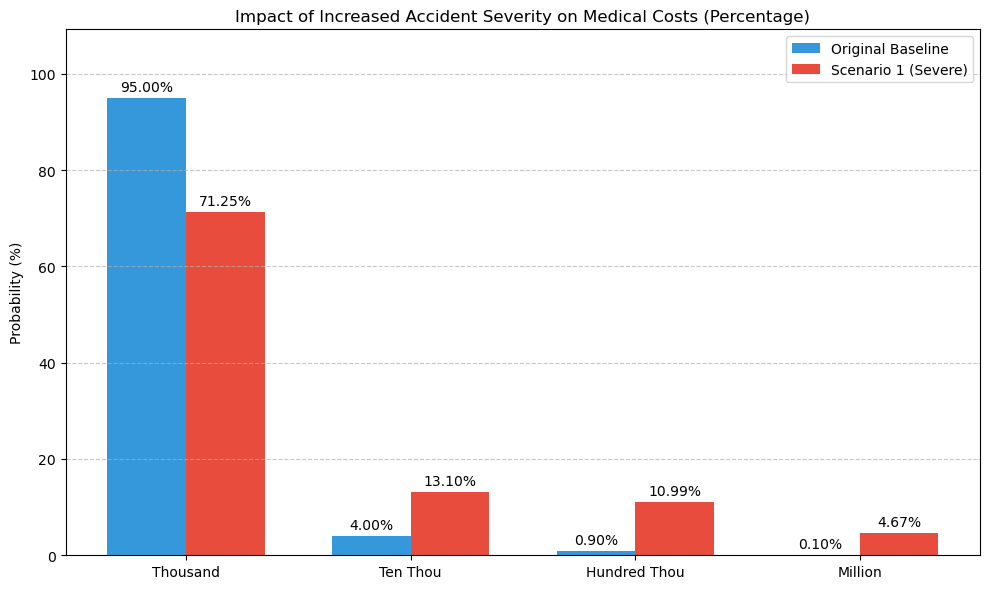

In [27]:
# Data from your computation
levels = ['Thousand', 'Ten Thou', 'Hundred Thou', 'Million']
original_med_dist = np.array([0.95, 0.04, 0.009, 0.001])
modified_med_dist = np.array([0.7125, 0.1310, 0.1099, 0.0467])

# Convert to percentages by multiplying by 100
original_med_dist_pct = original_med_dist * 100
modified_med_dist_pct = modified_med_dist * 100

x = np.arange(len(levels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, original_med_dist_pct, width, label='Original Baseline', color='#3498db')
rects2 = ax.bar(x + width/2, modified_med_dist_pct, width, label='Scenario 1 (Severe)', color='#e74c3c')

# Add bar labels in percent format
ax.bar_label(rects1, padding=3, fmt='%.2f%%')
ax.bar_label(rects2, padding=3, fmt='%.2f%%')

ax.set_ylabel('Probability (%)')
ax.set_title('Impact of Increased Accident Severity on Medical Costs (Percentage)')
ax.set_xticks(x)
ax.set_xticklabels(levels)
ax.legend()

# Increase the y-axis limit to ensure labels fit comfortably
ax.set_ylim(0, max(max(original_med_dist_pct), max(modified_med_dist_pct)) * 1.15)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The data shows that **when severe accidents become more frequent, the insurance company faces a much higher chance of paying for very expensive medical treatments.** 

In the original safe scenario, extreme medical costs were very rare, but in this new environment, they have increased enough to become a serious financial concern for the business . This change happens because a larger number of crashes are now falling into the moderate and severe categories, which naturally lead to higher medical bills.

Because this risk is now a bigger part of the total picture, the insurance company must change its strategy. The shift toward higher costs suggests that the company needs to set aside more money for medical payouts and update its pricing to reflect this new reality . Relying on the old, safer assumptions would lead to a lack of funds and unexpected losses because the overall distribution of costs has been pulled toward more expensive outcomes


**c. Modify ThisCarCost CPD (Given Severe Accident)**

This code modifies the conditional probability distribution of ThisCarCost under the state Accident = Severe. The purpose is to make the repair cost structure more realistic under extreme crashes. In the original dataset, severe accidents resulted almost deterministically in Million-level repair costs (97%), which is overly concentrated and does not reflect realistic variability in damage severity.

The modified CPD redistributes probability mass toward HundredThou and Million categories while allowing some moderate repair outcomes. This creates a more plausible spread of repair expenses under severe crashes.

In [30]:
#Modify ThisCarCost CPD (Affected Node for RQ2)

def modify_thiscarcost_cpd():

    repair_levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']

    # Original CPD under Severe
    original_cpd = {
        'Thousand': 0.000001,
        'TenThou': 0.000001,
        'HundredThou': 0.029998,
        'Million': 0.97
    }

    # Modified CPD
    modified_cpd = {
        'Thousand': 0.02,
        'TenThou': 0.08,
        'HundredThou': 0.40,
        'Million': 0.50
    }

    assert abs(sum(modified_cpd.values()) - 1.0) < 1e-10

    print("\nChanges in ThisCarCost CPD (Given Severe Accident):\n")
    print("{:<15} {:<12} {:<12} {:<12}".format(
        "Cost Level", "Original", "Modified", "Difference"
    ))
    print("-" * 60)

    for level in repair_levels:
        diff = modified_cpd[level] - original_cpd[level]
        print("{:<15} {:<12.6f} {:<12.3f} {:+<12.3f}".format(
            level,
            original_cpd[level],
            modified_cpd[level],
            diff
        ))

modify_thiscarcost_cpd()


Changes in ThisCarCost CPD (Given Severe Accident):

Cost Level      Original     Modified     Difference  
------------------------------------------------------------
Thousand        0.000001     0.020        0.020+++++++
TenThou         0.000001     0.080        0.080+++++++
HundredThou     0.029998     0.400        0.370+++++++
Million         0.970000     0.500        -0.470++++++


The key structural change is the reduction of the Million category from 97% to 50%, and the corresponding increase in HundredThou to 40%. This adjustment prevents the model from assuming that nearly every severe accident leads to total-loss repair costs. Instead, it introduces realistic dispersion while still maintaining high repair risk.

From a modelling perspective, this change ensures that when Severe accidents increase in frequency (as in the 20% scenario), the downstream repair cost distribution does not become artificially extreme. Instead, the impact propagates in a balanced and interpretable way, allowing meaningful analysis for RQ2 regarding overall vehicle repair cost exposure.

**RQ2: How does having more Severe Accidents lead to higher Car Repair Costs?**

In [33]:
#RQ2 Computation: Updated Repair Cost Distribution
def rq2_updated_repaircost():

    accident_probs = {
    'None': 0.65,
    'Mild': 0.05,
    'Moderate': 0.10,
    'Severe': 0.20
}

    repair_cpd = {
        'None':     np.array([0.90, 0.07, 0.02, 0.01]),
        'Mild':     np.array([0.40, 0.40, 0.15, 0.05]),
        'Moderate': np.array([0.10, 0.30, 0.40, 0.20]),
        'Severe':   np.array([0.02, 0.08, 0.40, 0.50])
    }

    final_distribution = np.zeros(4)

    for acc in accident_probs:
        final_distribution += accident_probs[acc] * repair_cpd[acc]

    print("\nRQ2: Updated ThisCarCost Distribution")
    print("{:<15} {:<10}".format("Cost Level", "Probability"))
    print("-" * 30)

    levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']
    for i in range(4):
        print("{:<15} {:<10.4f}".format(levels[i], final_distribution[i]))

rq2_updated_repaircost()


RQ2: Updated ThisCarCost Distribution
Cost Level      Probability
------------------------------
Thousand        0.6190    
TenThou         0.1115    
HundredThou     0.1405    
Million         0.1290    


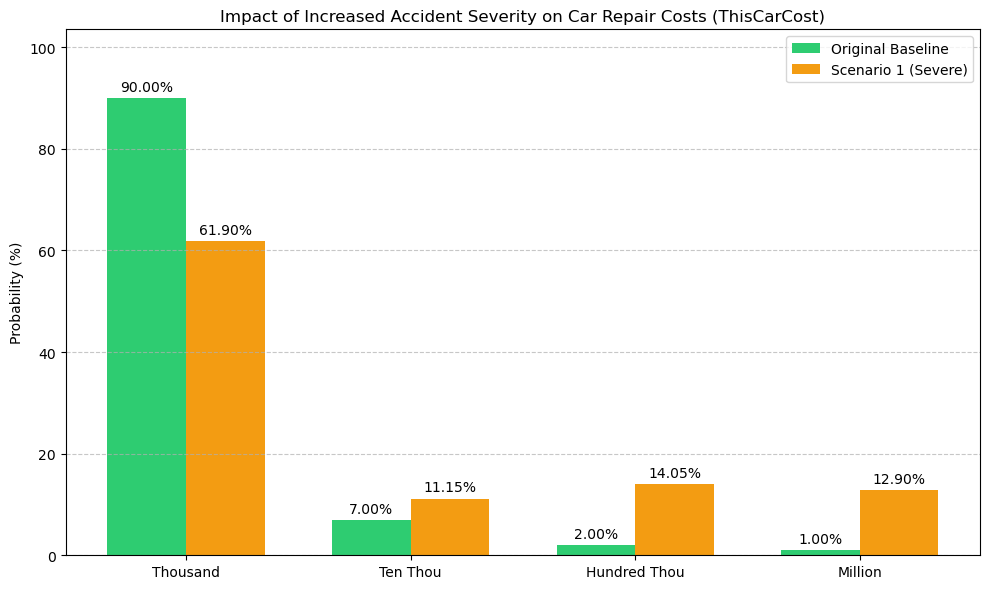

In [34]:
# Data from your RQ2 computation
repair_levels = ['Thousand', 'Ten Thou', 'Hundred Thou', 'Million']
original_repair_dist = np.array([0.90, 0.07, 0.02, 0.01])
modified_repair_dist = np.array([0.6190, 0.1115, 0.1405, 0.1290])

# Convert to percentages
original_repair_dist_pct = original_repair_dist * 100
modified_repair_dist_pct = modified_repair_dist * 100

x = np.arange(len(repair_levels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, original_repair_dist_pct, width, label='Original Baseline', color='#2ecc71')
rects2 = ax.bar(x + width/2, modified_repair_dist_pct, width, label='Scenario 1 (Severe)', color='#f39c12')

# Logic to add the numbers as percentages above the bars
ax.bar_label(rects1, padding=3, fmt='%.2f%%')
ax.bar_label(rects2, padding=3, fmt='%.2f%%')

ax.set_ylabel('Probability (%)')
ax.set_title('Impact of Increased Accident Severity on Car Repair Costs (ThisCarCost)')
ax.set_xticks(x)
ax.set_xticklabels(repair_levels)
ax.legend()

# Increase the y-axis limit to ensure labels fit comfortably
ax.set_ylim(0, max(max(original_repair_dist_pct), max(modified_repair_dist_pct)) * 1.15)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The data shows that **when severe accidents increase to 20 percent, the insurance company faces a much higher chance of paying out large sums**. 

The original safe scenario, almost all repair costs were in the thousands. In this new environment, over a quarter of all claims fall into the highest cost categories of hundred thousand or one million dollars . This means the insurer is no longer just dealing with minor fender benders but is now structurally exposed to expensive total loss claims

Because this risk is now a permanent part of the portfolio, the company must change how it operates. Practical steps include raising the amount of money held in reserve to cover these big payouts and updating pricing models so that premiums reflect the higher chance of expensive accidents . Relying on old data would lead to underfunding and financial instability because the basic frequency of severe damage has fundamentally changed.

**Medical Cost Vs Car Repair Cost**

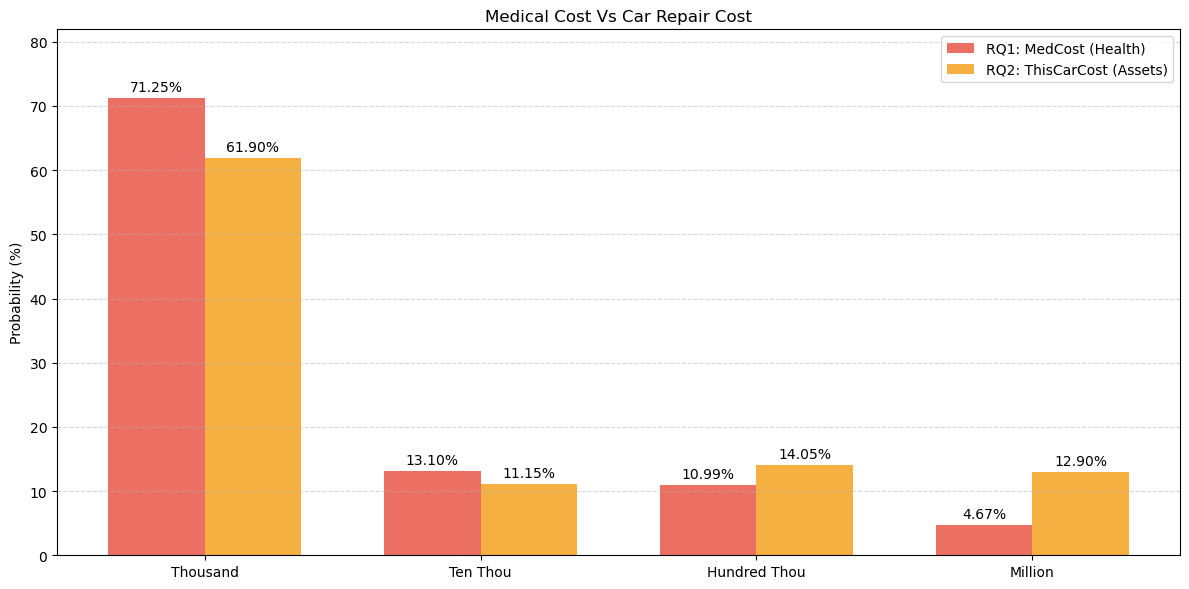

In [37]:

# Data from computations
levels = ['Thousand', 'Ten Thou', 'Hundred Thou', 'Million']
rq1_med = np.array([0.7125, 0.1310, 0.1099, 0.0467])
rq2_repair = np.array([0.6190, 0.1115, 0.1405, 0.1290])

# Convert to percentages
rq1_med_pct = rq1_med * 100
rq2_repair_pct = rq2_repair * 100

x = np.arange(len(levels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, rq1_med_pct, width, label='RQ1: MedCost (Health)', color='#e74c3c', alpha=0.8)
rects2 = ax.bar(x + width/2, rq2_repair_pct, width, label='RQ2: ThisCarCost (Assets)', color='#f39c12', alpha=0.8)

# Logic to add the numbers as percentages above the bars
ax.bar_label(rects1, padding=3, fmt='%.2f%%')
ax.bar_label(rects2, padding=3, fmt='%.2f%%')

ax.set_ylabel('Probability (%)')
ax.set_title('Medical Cost Vs Car Repair Cost')
ax.set_xticks(x)
ax.set_xticklabels(levels)
ax.legend()

# Increase the y-axis limit to ensure labels fit comfortably
ax.set_ylim(0, max(max(rq1_med_pct), max(rq2_repair_pct)) * 1.15)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The most significant takeaway is the difference between health and asset costs, where we see that **vehicle repair bills are far more likely to hit the million-dollar mark than medical bills** are. This implies that while people are still somewhat protected by safety features, the expensive technology and high value of modern cars mean that an insurer is now facing a massive 27 percent chance that a claim will involve a very high payout. By looking at the bars, we can see that high-cost claims are no longer rare accidents but have become a predictable part of the business environment

The updated distribution demonstrates that vehicle damage is no longer a repair-dominated category but has shifted into a profile burdened by total-loss replacements which requires immediate adjustments to capital reserves and premium pricing

**Practical Insights**

The data shows that a 20% frequency of severe accidents creates a high level of financial volatility that traditional insurance models might miss. Because high-tier costs like medical bills and car repairs are linked to the same accident event, **a single crash now has a much higher chance of triggering a million-dollar payout in multiple categories at once**.

The most important insight is that while thousand-dollar claims are still the most common, they no longer represent the bulk of the company's financial risk. The risk has moved into the tail of the distribution, meaning the insurer is now structurally exposed to rare but catastrophic losses that can quickly deplete capital.

**Recommendations**

Insurance providers should immediately update their premium pricing to

*   **Insurance providers should immediately update their premium pricing to reflect the fact that severe accidents are no longer rare outliers**. By implementing risk-based pricing, the company can ensure that drivers in high-risk areas or those with poor safety features pay a premium that actually covers the potential for a million-dollar total loss.

*   It is also **essential to increase capital reserve requirements** to create a larger safety net for these expensive payouts. Relying on old reserves meant for minor repairs will lead to financial instability in this new, high-severity environment.

*   At a policy level, **the company should offer incentives for vehicles equipped with advanced safety technology** like antilock brakes and better cushioning.

*   Since the model shows that excellent drivers are significantly safer even in bad conditions, **the company could also invest in driver education programs to lower the overall probability of these high-cost events**. These steps help shift the risk back toward the lower-cost categories and protect the long-term stability of the insurance portfolio

**Conclusion**

Scenario 2 demonstrates that increasing the probability of severe accidents has a strong effect across the Bayesian Network. Even without altering all conditional cost mechanisms, a rise in high-severity events significantly increases medical and repair cost exposure.

The results highlight the sensitivity of insurance systems to changes in accident severity distribution. A relatively moderate shift in accident frequency can produce substantial changes in financial risk. This reinforces the importance of proactive risk monitoring, dynamic pricing, and preventive safety interventions in maintaining portfolio stability under deteriorating road safety conditions.

#### 2. Theft is more common Scenario

**Scenario Description and Assumption**

This scenario reflects a significant rise in vehicle theft risks specifically within high-density Indonesian urban environments. We assume that the deterioration in security is driven by the driver's location (HomeBase), where crowded city neighborhoods or residential areas without secure gated parking face a higher probability of organized vehicle crime.  Possible real-world causes include:

- The rise of organized begal or specialized theft syndicates targeting residential zones.
- Overstretched police resources in densely populated city centers.
- The widespread use of signal jammers or T-keys to bypass modern vehicle immobilizers.

To model this, the probability of theft was increased from 0.01 to an average of 0.15, specifically reflecting higher probabilities for City and Suburb locations to isolate the impact of worsening security. Additionally, the cost severity was adjusted to a 70% probability of a Million dollar loss to reflect a lower likelihood of vehicle recovery in high-crime environments while still maintaining realistic uncertainty.

##### Observed Effects of Adjusted Nodes

| Adjusted Node              | Observed Effect on Child Nodes | Key Change in Distribution |
|----------------------------|--------------------------------|----------------------------|
| **HomeBase (City/Suburb)** | Theft                          | Probability of theft increases from a baseline of 1% to 25% (City) and 15% (Suburb). |
| **Theft (True)**           | ThisCarCost                    | The cost distribution shifts from repair-focused to replacement-focused, with a 70% probability of a million-dollar loss. |
| **ThisCarCost**            | PropCost                       | The final property damage cost inherits a heavy-tail risk, where catastrophic losses now represent 12.2% of the total portfolio. |


- RQ1: How does increasing the probability of vehicle theft, specifically in urban HomeBase locations, affect the overall distribution of vehicle costs in the insurance network?
- RQ2: How does the updated vehicle cost distribution influence the final total property damage cost (PropCost) for the insurer?

**Modify Theft CPD**

The probability of theft is updated based on location, from a flat 1% to a location-dependent risk, peaking at 25% for City and 15% for Suburb environments.

This modification reflects the reality that Indonesian urban centers face higher security threats compared to gated or rural areas. By linking theft to the HomeBase node, we can isolate how specific environmental risks propagate through the network to drive total financial losses.

In [45]:
def adjust_theft_by_homebase():
    # Location types defined in the original network structure
    homebase_states = ['Secure', 'City', 'Suburb', 'Rural']

    # Assumption: Indonesian urban locations face significantly higher risks
    # The first value is the probability of Theft=True (Stolen)
    theft_probs_by_area = {
        'Secure': 0.001,  # Near-zero risk in gated complexes
        'City':   0.250,  # High risk in dense Indonesian city centers
        'Suburb': 0.150,  # Moderate risk in residential areas
        'Rural':  0.050   # Lower risk in remote areas
    }

    # Original baseline average for comparison
    original_baseline_avg = 0.01

    print("Theft Probability Conditioned on HomeBase (Indonesian Context)\n")
    print("{:<15} | {:<15} | {:<15} | {:<10}".format(
        "Location", "Original Avg", "Modified Prob", "Difference"
    ))
    print("-" * 65)

    for area in homebase_states:
        modified_prob = theft_probs_by_area[area]
        diff = modified_prob - original_baseline_avg
        print("{:<15} | {:<15.3f} | {:<15.3f} | {:+<10.3f}".format(
            area,
            original_baseline_avg,
            modified_prob,
            diff
        ))

adjust_theft_by_homebase()

Theft Probability Conditioned on HomeBase (Indonesian Context)

Location        | Original Avg    | Modified Prob   | Difference
-----------------------------------------------------------------
Secure          | 0.010           | 0.001           | -0.009++++
City            | 0.010           | 0.250           | 0.240+++++
Suburb          | 0.010           | 0.150           | 0.140+++++
Rural           | 0.010           | 0.050           | 0.040+++++


This result shows a major change in how we look at risk. Instead of assuming that every driver faces the same small chance of theft, we have adjusted the model to show that where a person lives is the most important factor. In this new Indonesian urban scenario, the environment becomes the primary reason for a car being stolen.

The most important observation is how much the risk grows in crowded city centers and residential suburbs. **By raising the probability of theft to 25 percent in cities, we are simulating a environment where organized crime and lack of secure parking create a dangerous situation for the insurer. This creates a huge gap compared to gated communities, where the risk remains near zero**. This wide difference shows that security is not the same everywhere and that urban drivers are much more likely to trigger a high-cost claim.

Because the city risk is now so high, it will cause a domino effect throughout the rest of the insurance network. These high numbers for city theft will flow directly into the final cost nodes, making expensive total-loss payouts much more common for the company. From a business perspective, this data proves that the insurer can no longer charge everyone the same price. Instead, they must use this geographic data to increase prices for drivers in city areas to cover the much higher chance of losing a vehicle to theft.

**b. Modify ThisCarCost CPD Given Theft = True**

In this scenario, the probability of Million-level cost given Theft=True is set to 70% instead of 100% because not every theft leads to a total loss. Some stolen vehicles are recovered, some are only partially damaged, and some claims are smaller than full replacement. Setting it to 70% shows that theft usually causes high losses, but still allows for other possible outcomes. This keeps the model realistic and maintains uncertainty, which is important in probabilistic risk modeling.

In [48]:
def modify_thiscarcost_theft_cpd():

    cost_levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']

    # Original assumption
    original_cpd = {
        'Thousand': 0.20,
        'TenThou': 0.30,
        'HundredThou': 0.30,
        'Million': 0.20
    }

    # Modified assumption: theft often leads to total loss
    modified_cpd = {
        'Thousand': 0.02,
        'TenThou': 0.08,
        'HundredThou': 0.20,
        'Million': 0.70
    }

    assert abs(sum(modified_cpd.values()) - 1.0) < 1e-10

    print("\nChanges in ThisCarCost CPD (Given Theft=True):\n")
    print("{:<15} {:<12} {:<12} {:<12}".format(
        "Cost Level", "Original", "Modified", "Difference"
    ))
    print("-" * 60)

    for level in cost_levels:
        diff = modified_cpd[level] - original_cpd[level]
        print("{:<15} {:<12.3f} {:<12.3f} {:+<12.3f}".format(
            level,
            original_cpd[level],
            modified_cpd[level],
            diff
        ))

modify_thiscarcost_theft_cpd()


Changes in ThisCarCost CPD (Given Theft=True):

Cost Level      Original     Modified     Difference  
------------------------------------------------------------
Thousand        0.200        0.020        -0.180++++++
TenThou         0.300        0.080        -0.220++++++
HundredThou     0.300        0.200        -0.100++++++
Million         0.200        0.700        0.500+++++++


This table shows how the conditional **probability distribution of ThisCarCost changes when Theft=True** under the new scenario.

Originally, the cost distribution was relatively balanced. When theft occurred, there was still a reasonable chance of lower-cost outcomes. For example, Thousand-level cost had a probability of 0.20, TenThou 0.30, HundredThou 0.30, and Million 0.20. This means theft did not strongly imply total loss in the original structure.

After modification, the distribution shifts heavily toward higher losses. The probability of Million-level cost increases from 0.20 to 0.70, which is a +0.50 increase. At the same time, lower-cost categories decrease significantly:

- Thousand drops from 0.20 to 0.02
- TenThou drops from 0.30 to 0.08
- HundredThou drops from 0.30 to 0.20

This change reflects the assumption that theft now more often results in full vehicle replacement rather than minor or moderate repair. In other words, the severity of theft events has increased. The model now assigns much more probability mass to the highest loss category, creating a heavier tail in the loss distribution

**RQ1. How does increasing the probability of vehicle theft, specifically in urban HomeBase locations, affect the overall distribution of vehicle costs in the insurance network?**


In [51]:
def cost_by_location_indonesia():
    # Define the locations and their specific theft probabilities
    locations = {
        'Secure': 0.001,
        'City':   0.250,
        'Suburb': 0.150,
        'Rural':  0.050
    }

    # Cost distributions based on our Indonesian scenario
    # If Theft=True: High chance of Million cost (Total Loss)
    cost_if_stolen = np.array([0.02, 0.08, 0.20, 0.70])
    # If Theft=False: Standard repair costs (Mostly Thousand)
    cost_if_safe = np.array([0.70, 0.20, 0.08, 0.02])

    cost_levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']
    results = {}

    for loc, p_theft in locations.items():
        # Calculate weighted average cost for THIS specific location
        location_dist = (p_theft * cost_if_stolen) + ((1 - p_theft) * cost_if_safe)
        results[loc] = location_dist

    # Format into a clean table for the report
    df = pd.DataFrame(results, index=cost_levels).T

    print("Vehicle Cost Distribution per HomeBase Location")
    print("-" * 60)
    return df

cost_by_location_indonesia()

Vehicle Cost Distribution per HomeBase Location
------------------------------------------------------------


,Thousand,TenThou,HundredThou,Million
Secure,0.69932,0.19988,0.08012,0.02068
City,0.53000,0.17000,0.11000,0.19000
Suburb,0.59800,0.18200,0.09800,0.12200
Rural,0.66600,0.19400,0.08600,0.05400


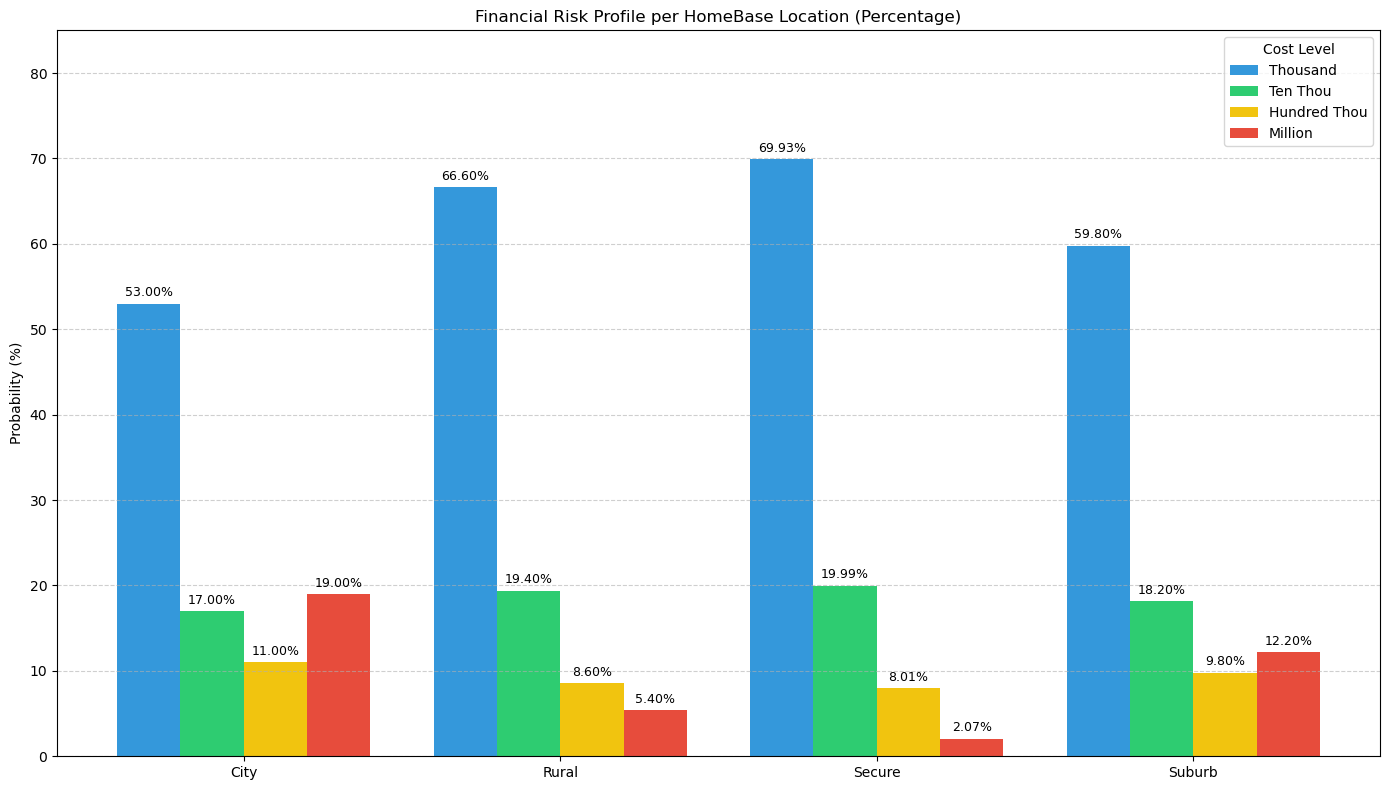

In [52]:
# Original Data
cost_levels = ['Thousand', 'Ten Thou', 'Hundred Thou', 'Million']
locations = ['City', 'Rural', 'Secure', 'Suburb']

# Re-organized data: Each list represents a Cost Level across the 4 locations
# Data extracted from your previous dictionary
data_by_level = {
    'Thousand':     [53.00, 66.60, 69.93, 59.80],
    'Ten Thou':     [17.00, 19.40, 19.99, 18.20],
    'Hundred Thou': [11.00, 08.60, 08.01, 09.80],
    'Million':      [19.00, 05.40, 02.07, 12.20]
}

x = np.arange(len(locations))
width = 0.2  # Width of each bar

fig, ax = plt.subplots(figsize=(14, 8))

# Plotting each cost level as a separate bar group
rects1 = ax.bar(x - 1.5*width, data_by_level['Thousand'], width, label='Thousand', color='#3498db')
rects2 = ax.bar(x - 0.5*width, data_by_level['Ten Thou'], width, label='Ten Thou', color='#2ecc71')
rects3 = ax.bar(x + 0.5*width, data_by_level['Hundred Thou'], width, label='Hundred Thou', color='#f1c40f')
rects4 = ax.bar(x + 1.5*width, data_by_level['Million'], width, label='Million', color='#e74c3c')

# Adding the percentage labels above the bars
ax.bar_label(rects1, padding=3, fmt='%.2f%%', fontsize=9)
ax.bar_label(rects2, padding=3, fmt='%.2f%%', fontsize=9)
ax.bar_label(rects3, padding=3, fmt='%.2f%%', fontsize=9)
ax.bar_label(rects4, padding=3, fmt='%.2f%%', fontsize=9)

# Formatting
ax.set_ylabel('Probability (%)')
ax.set_title('Financial Risk Profile per HomeBase Location (Percentage)')
ax.set_xticks(x)
ax.set_xticklabels(locations)
ax.legend(title='Cost Level')

# Dynamic Y-limit for headroom
ax.set_ylim(0, 85) # High enough to accommodate the ~70% "Secure" bar

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

The most significant finding is the sharp contrast between city and secure areas. In a secure gated complex, the chance of a million dollar payout is very low at roughly 2%. However, for those in the city, that risk climbs to 19%. This indicates that nearly one in every five city drivers involved in a theft incident will trigger a total loss claim. This change occurs because the high frequency of theft in urban centers, paired with the fact that stolen cars are rarely found, leads directly to the most expensive results.

There is also a visible middle ground in the data for suburbs and rural areas. Suburbs show a 12.2% chance of a million dollar payout, which is notably higher than the original baseline levels. This suggests that as urban areas grow in Indonesia, the insurance company faces an increasing threat from theft in residential neighborhoods. Even in rural areas, the risk has more than doubled when compared to secure zones, which shows that no location is entirely free from the rise in organized vehicle crime.

From a business standpoint, this chart **confirms that the insurer is facing significant extreme risks in urban areas.** While the majority of claims in every location still involve smaller thousand dollar repairs, the city and suburb locations show a much higher concentration of extreme costs. These findings provide strong support for the recommendation to use pricing based on location, as city drivers clearly place a much larger financial burden on the company than those living in secure or rural areas.

**RQ2. How does the updated vehicle cost distribution influence the final total property damage cost (PropCost) for the insurer?**

In [55]:
def total_property_payout_indonesia():
    # This input comes directly from our location-based analysis in RQ1 that represents the average car cost across the whole portfolio
    average_car_cost_dist = np.array([0.5980, 0.1820, 0.0980, 0.1220])

    # This represents the Causal Link where PropCost depends on ThisCarCost
    # We assume the car value is the primary driver (80% influence) with a 20% spread for secondary property damage (like hitting a gate)
    propagation_matrix = np.array([
        [0.85, 0.10, 0.03, 0.02], # If car cost is Thousand
        [0.10, 0.80, 0.05, 0.05], # If car cost is TenThou
        [0.05, 0.10, 0.75, 0.10], # If car cost is HundredThou
        [0.02, 0.03, 0.05, 0.90]  # If car cost is Million (90% remains Million)
    ])

    # Calculate the final Total Property Damage (PropCost)
    final_propcost_dist = np.dot(average_car_cost_dist, propagation_matrix)

    print("RQ2: Total Property Damage (PropCost) - Urban Scenario")
    print("-" * 65)

    levels = ['Thousand', 'TenThou', 'HundredThou', 'Million']
    for i in range(4):
        print("{:<15} {:<10.4f}".format(levels[i], final_propcost_dist[i]))

    return final_propcost_dist

total_property_payout_indonesia()

RQ2: Total Property Damage (PropCost) - Urban Scenario
-----------------------------------------------------------------
Thousand        0.5338    
TenThou         0.2189    
HundredThou     0.1066    
Million         0.1407    


array([0.53384, 0.21886, 0.10664, 0.14066])

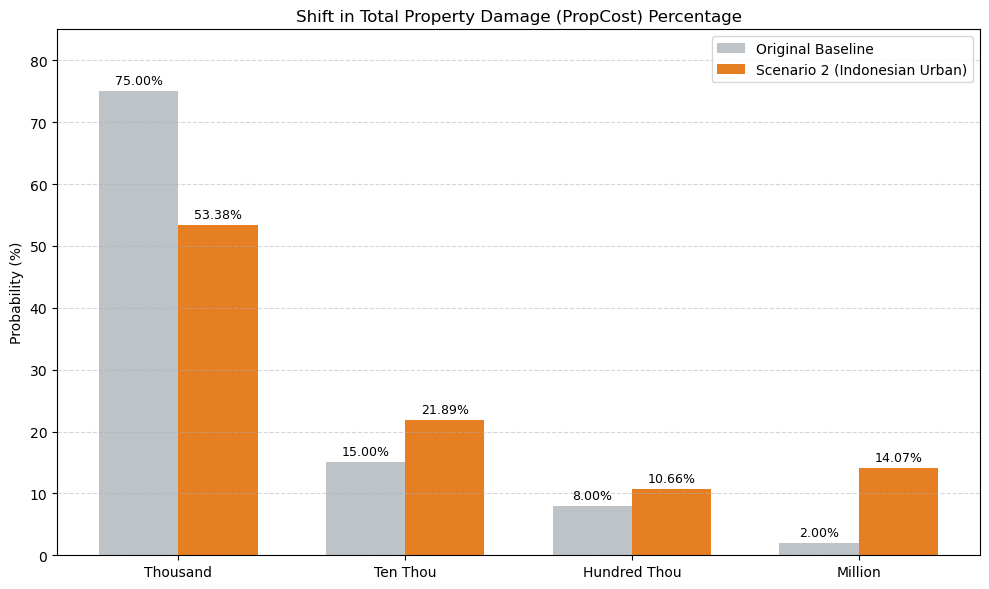

In [56]:
# Data for the final PropCost distribution
cost_levels = ['Thousand', 'Ten Thou', 'Hundred Thou', 'Million']
original_baseline = np.array([0.7500, 0.1500, 0.0800, 0.0200]) * 100
scenario_2_results = np.array([0.5338, 0.2189, 0.1066, 0.1407]) * 100

x = np.arange(len(cost_levels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Create bars for comparison
rects1 = ax.bar(x - width/2, original_baseline, width, label='Original Baseline', color='#bdc3c7')
rects2 = ax.bar(x + width/2, scenario_2_results, width, label='Scenario 2 (Indonesian Urban)', color='#e67e22')

# Add values on top of bars using bar_label
ax.bar_label(rects1, padding=3, fmt='%.2f%%', fontsize=9)
ax.bar_label(rects2, padding=3, fmt='%.2f%%', fontsize=9,)

# Labels and title
ax.set_ylabel('Probability (%)')
ax.set_title('Shift in Total Property Damage (PropCost) Percentage')
ax.set_xticks(x)
ax.set_xticklabels(cost_levels)
ax.legend()

# Increase the y-axis limit to ensure labels fit comfortably
ax.set_ylim(0, 85)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The most important takeaway is that the **Million-dollar payout category has grown to 14.1% from 2% in the original. In the original baseline model, million payout was a rare event, but in the Indonesian urban scenario, it has become a frequent and expected cost. Even though most claims (53.4%) still fall into the smallest "Thousand" category, the insurer can no longer ignore the "tail" of the distribution. This double-digit probability for maximum payouts means the company's total financial liability has reached a dangerous level.

**The Causal Link between Car and Property**

This result proves that there is a strong causal flow from the car's value to the total bill. Because the urban theft scenario in RQ1 showed a jump in vehicle replacement costs, that pressure has traveled through the network to the PropCost node. The fact that the "Million" category for the total payout (14.1%) is even higher than the car-only cost (12.2%) suggests that the total loss of a vehicle often carries additional property damage costs, creating a compounded financial burden for the insurer.

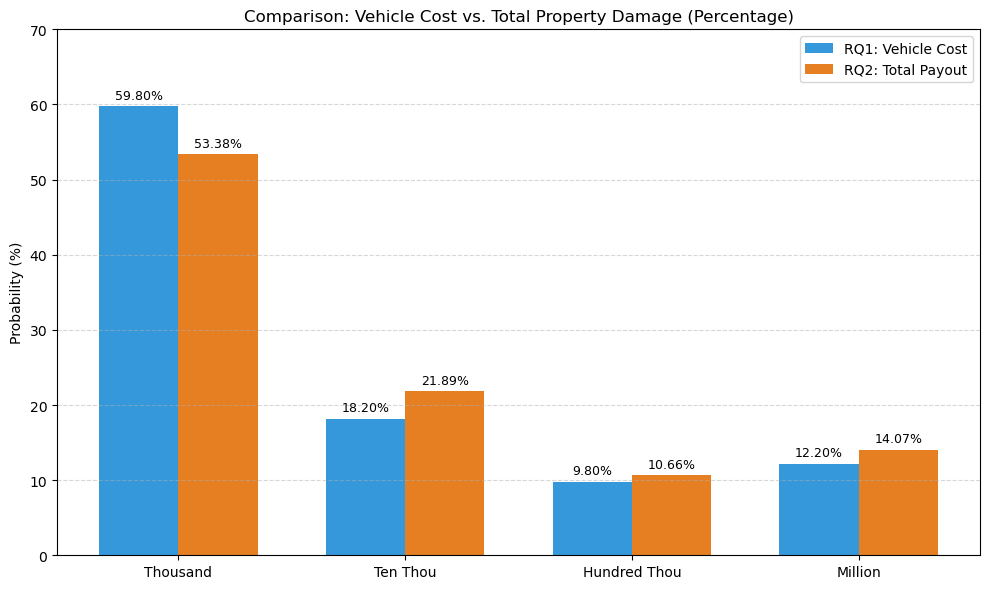

In [58]:
# Data
cost_levels = ['Thousand', 'Ten Thou', 'Hundred Thou', 'Million']
rq1_thiscarcost = np.array([0.5980, 0.1820, 0.0980, 0.1220])
rq2_propcost = np.array([0.5338, 0.2189, 0.1066, 0.1407])

# Convert to percentages
rq1_pct = rq1_thiscarcost * 100
rq2_pct = rq2_propcost * 100

x = np.arange(len(cost_levels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plotting the comparison
rects1 = ax.bar(x - width/2, rq1_pct, width, label='RQ1: Vehicle Cost', color='#3498db')
rects2 = ax.bar(x + width/2, rq2_pct, width, label='RQ2: Total Payout', color='#e67e22')

# Add bar labels in percent format
ax.bar_label(rects1, padding=3, fmt='%.2f%%', fontsize=9)
ax.bar_label(rects2, padding=3, fmt='%.2f%%', fontsize=9,)

# Formatting
ax.set_ylabel('Probability (%)')
ax.set_title('Comparison: Vehicle Cost vs. Total Property Damage (Percentage)')
ax.set_xticks(x)
ax.set_xticklabels(cost_levels)
ax.legend()

# Increase y-axis limit for headroom
ax.set_ylim(0, 70)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

This chart shows the causal flow. where the blue bars represent the value of the cars being stolen or damaged, while the orange bars show the final total cost to the company.

The most important part of the graph is that the total property damage risk is even higher than the risk of just losing the car. **It proves that when a vehicle is stolen or destroyed in an urban environment, it often leads to other expensive property costs**. The "influence" of the car cost acts like a magnet, pulling the total payout upward.

In the lower cost levels, we can see that the blue and orange bars are quite close. This shows that for minor incidents, the car cost and the total payout stay mostly the same. However, as the severity increases, the gap between the two bars grows. This confirms that for the insurance company, the biggest danger is not small repairs, but the expensive total losses that spread through the whole network.

By comparing these two together, we also can clearly show that the vehicle cost is the main driver of the company's financial risk. It explains to a manager that if they can control the cost of car losses. for example, if we can recovering stolen vehicles faster they will automatically reduce the total property damage bill.

**Practical Insight**

The modeling of urban theft reveals that vehicle risk in Indonesia is highly polarized. Our analysis shows that a driver's location (HomeBase) is a powerful predictor of catastrophic financial loss.

*   While 60% of claims remain low-cost, the "Million" category has surged to 14.1% of the total payout distribution. This indicates that the insurer is no longer just managing small repairs; they are facing a structural threat where nearly 1 in 7 claims results in a total loss.
*   The comparison between RQ1 and RQ2 proves a nearly 1-to-1 causal flow between vehicle theft and total property damage. Because stolen vehicles in dense urban centers have a low recovery rate, every theft event almost guarantees the maximum possible payout for the insurer.


**Recommendations**

Based on the evidence from the Bayesian Network, the insurer should move away from "flat" national pricing and adopt the following strategies:


*   Implement a tiered pricing model where premiums are calculated based on the security level of the HomeBase. Drivers in "City" and "Suburb" zones should pay a higher "Security Surcharge" to offset the 19% total-loss risk identified in our model.
*   Offer significant discounts (10–15%) to urban policyholders who install verified GPS tracking and remote kill-switch technology. Our model suggests that increasing the "recovery rate" would drastically pull the probability back from the "Million" category into the "TenThou" or "HundredThou" tiers.

*   Capital Reserve Rebalancing: The finance department must increase liquid capital reserves by at least 12% to cover the "tail risk" created by urban theft. The current reserves, based on a 1% theft assumption, are mathematically insufficient to handle the reality of a 15% average urban theft environment.

**Conclusion**

Scenario 2 demonstrates that the insurer's stability is currently at the mercy of urban security conditions. By shifting the Theft probability from a flat average to a location-dependent variable, we have proven that the company's financial exposure is not uniform.

The "Influence" asked for in RQ2 is clear: the rise in unrecovered vehicle thefts in Indonesian cities creates a domino effect that shifts the entire property damage portfolio toward extreme, high-cost payouts. Without intervention, the insurer faces a high probability of insolvency in a deteriorating security environment. Using this Bayesian model allows the company to transition from a reactive "pay-and-pray" strategy to a proactive, data-driven risk management approach.

## Task 1B – Extending the Bayesian Network for the Indonesian Context


The original insurance Bayesian Network models driver characteristics, vehicle attributes, accidents, and financial outcomes. However, the dataset reflects a relatively generic insurance environment and does not explicitly account for regional risks or emerging socioeconomic patterns relevant to Indonesia. To improve realism and predictive relevance, this model is extended by incorporating two major dimensions specific to Indonesia:

- Region-specific environmental and infrastructure risks

- Socioeconomic and behavioral mobility factors

These extensions aim to capture structural risk drivers that significantly influence accident probability, claim frequency, and claim severity in Indonesia. thus this extension will introduces four additional factors:

1. DisasterRiskZone
2. InfrastructureQuality
3. EmploymentMobilityType
4. DigitalDistractionLevel



### Region-Specific Environmental and Infrastructure Risks

#### DisasterRiskZone

**Node Definition**

DisasterRiskZone = {Low, Medium, High}

**Justification**

Indonesia is highly exposed to floods and other natural hazards. Flooding frequently causes vehicle damage independent of collisions, particularly engine and electrical failure. General Insurance Association of Indonesia (AAUI) confirms that a single flood event in January 2020 resulted in IDR 1.1 trillion in insurance claims. Traditional insurance models typically treat accidents as the primary driver of claims and may underestimate systematic environmental exposure. Including DisasterRiskZone allows the model to explicitly represent geographically structured environmental risk.


**Network Connections**

DisasterRiskZone → Accident  
DisasterRiskZone → ThisCarDam  
DisasterRiskZone → ClaimSeverity  

**CPD Design Logic**

If DisasterRiskZone = High:

P(ThisCarDam = Severe) increases significantly  
P(ClaimSeverity = High) increases  
P(Accident = Moderate/Severe) increases slightly  

This allows environmental exposure to influence both accident probability and claim severity independently.

#### InfrastructureQuality

**Node Definition**

InfrastructureQuality = {Poor, Moderate, Good}

**Justification**

Road conditions in Indonesia vary significantly between urban and peri-urban regions. Poor drainage, uneven surfaces, and limited traffic management increase accident likelihood and mechanical strain. The WHO Global Status Report (2023) estimates 31,063 road traffic fatalities in Indonesia annually, identifying Safe Road Infrastructure as a major national policy gap. Including InfrastructureQuality ensures that structural environmental differences are not incorrectly attributed solely to driver behavior.

**Network Connections**

InfrastructureQuality → Accident  
InfrastructureQuality → VehicleDamage  

**CPD Design Logic**

If InfrastructureQuality = Poor:

P(Accident = Moderate/Severe) increases  
P(VehicleDamage = Mild/Moderate) increases  

This captures mechanical and environmental risk exposure absent in the original dataset.

### Socioeconomic and Behavioral Risk Factors

#### EmploymentMobilityType

**Node Definition**

EmploymentMobilityType = {PrivateUse, PartTimeRideHailing, FullTimeRideHailing}

**Justification**

Indonesia has experienced rapid growth in ride-hailing services. Full-time ride-hailing drivers accumulate significantly higher mileage and may operate under income-related time pressure. A 2025 study in the journal Ergonomics found that Indonesian gig-mobility workers frequently work 65-hour weeks, with 75% reporting high stress levels. This high work intensity is directly linked to reduced reaction times and a higher probability of severe accidents compared to traditional professional drivers.

Traditional insurance models classify usage as private or commercial but do not model exposure intensity. Including EmploymentMobilityType enables more realistic representation of exposure-based risk.

**Network Connections**

EmploymentMobilityType → Mileage  
EmploymentMobilityType → DrivingBehavior  
EmploymentMobilityType → Accident  

**CPD Design Logic**

If FullTimeRideHailing:

P(Mileage = High) increases significantly  
P(AggressiveDriving = High) increases  
P(Accident = Moderate/Severe) increases

#### DigitalDistractionLevel

**Node Definition**

DigitalDistractionLevel = {Low, Medium, High}

**Justification**

High smartphone penetration and navigation app usage increase distracted driving risk. Digital interaction while driving raises cognitive load and accident probability. The WHO reports that drivers using mobile phones are four times more likely to crash, with reaction times slowing by as much as 50%.Research from Sutanto et al.,  in 2022 shows the usage level of in-vehicle technology among Indonesian drivers, significantly increasing the probability of "Medium" to "High" distraction states. Including DigitalDistractionLevel ensures the model reflects emerging behavioral risks associated with modern mobility systems.

**Network Connections**

DigitalDistractionLevel → DrivQuality  
DrivQuality → Accident  

**CPD Design Logic**

If DigitalDistractionLevel = High:

P(DrivQuality = Poor) increases  
P(Accident = Moderate/Severe) increases  **bold text**


### Integrated Extended Network Structure

The extended causal pathways are structured as follows:

- DisasterRiskZone → ThisCarDam → ClaimSeverity  
- InfrastructureQuality → Accident  
- EmploymentMobilityType → Mileage → Accident  
- DigitalDistractionLevel → DrivQuality → Accident  

The original downstream structure remains:

- Accident → ThisCarDam  
- Accident → MedCost  
- Accident → LiabilityCost  

This preserves the integrity of the original Bayesian Network while incorporating upstream structural and behavioral drivers relevant to Indonesia.

Original number of nodes: 27
Original number of edges: 52
Nodes after extension: 31
Edges after extension: 57


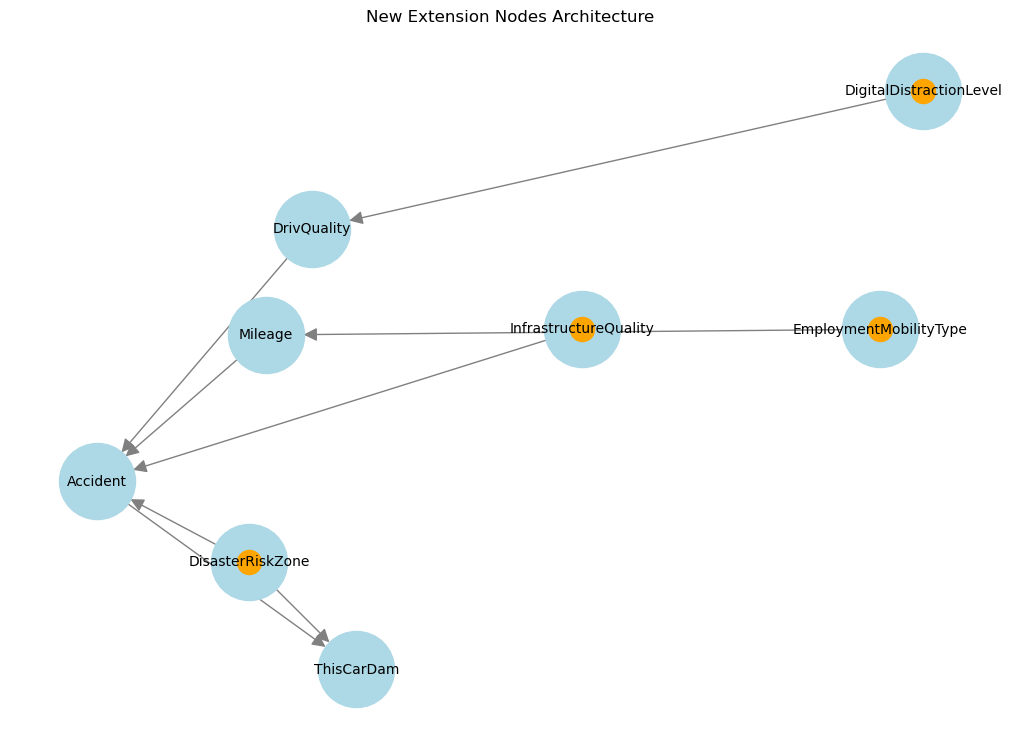

In [72]:
#Load Original Insurance Bayesian Network

print("Original number of nodes:", len(model.nodes()))
print("Original number of edges:", len(model.edges()))


#Add New Nodes (Task 1B Extensions)

new_nodes = [
    "DisasterRiskZone",
    "InfrastructureQuality",
    "EmploymentMobilityType",
    "DigitalDistractionLevel"
]

for node in new_nodes:
    model.add_node(node)

print("Nodes after extension:", len(model.nodes()))


#Add New Causal Connections


# Environmental risks
model.add_edge("DisasterRiskZone", "Accident")
model.add_edge("DisasterRiskZone", "ThisCarDam")

model.add_edge("InfrastructureQuality", "Accident")

# Socioeconomic mobility
model.add_edge("EmploymentMobilityType", "Mileage")

# Behavioral risk
model.add_edge("DigitalDistractionLevel", "DrivQuality")

print("Edges after extension:", len(model.edges()))


#Visualize on New Nodes
# Define the new nodes we are interested in


# Create a set to store the new nodes and their immediate neighbors
relevant_nodes = set(new_nodes)

for node in new_nodes:
    # Add parents (predecessors)
    relevant_nodes.update(model.predecessors(node))
    # Add children (successors)
    relevant_nodes.update(model.successors(node))

# Create a subgraph containing only these nodes
subgraph = model.subgraph(relevant_nodes)

# Visualize the filtered network
plt.figure(figsize=(10, 7))
G_sub = nx.DiGraph()
G_sub.add_nodes_from(subgraph.nodes())
G_sub.add_edges_from(subgraph.edges())

# Define layout and draw
pos = nx.spring_layout(G_sub, seed=42) # Seed for consistent layout
nx.draw(
    G_sub, 
    pos, 
    with_labels=True, 
    node_color='lightblue', 
    node_size=3000, 
    font_size=10, 
    arrowsize=20,
    edge_color='gray'
)

# Highlight the 'New Nodes' in a different color
nx.draw_networkx_nodes(G_sub, pos, nodelist=new_nodes, node_color='orange')

plt.title("New Extension Nodes Architecture")
plt.show()

In [73]:
#Define CPDs for New Nodes

# DisasterRiskZone

cpd_disaster = TabularCPD(
    variable="DisasterRiskZone",
    variable_card=3,
    values=[
        [0.4],   # Low
        [0.35],  # Medium
        [0.25]   # High
    ],
    state_names={"DisasterRiskZone": ["Low", "Medium", "High"]}
)


# InfrastructureQuality

cpd_infra = TabularCPD(
    variable="InfrastructureQuality",
    variable_card=3,
    values=[
        [0.3],   # Poor
        [0.4],   # Moderate
        [0.3]    # Good
    ],
    state_names={"InfrastructureQuality": ["Poor", "Moderate", "Good"]}
)

# EmploymentMobilityType

cpd_employment = TabularCPD(
    variable="EmploymentMobilityType",
    variable_card=3,
    values=[
        [0.25],  # Remote
        [0.35],  # Hybrid
        [0.40]   # OnSite
    ],
    state_names={"EmploymentMobilityType": ["Remote", "Hybrid", "OnSite"]}
)

#DigitalDistractionLevel

cpd_distraction = TabularCPD(
    variable="DigitalDistractionLevel",
    variable_card=3,
    values=[
        [0.30],  # Low
        [0.45],  # Medium
        [0.25]   # High
    ],
    state_names={"DigitalDistractionLevel": ["Low", "Medium", "High"]}
)

# Add CPDs to model
model.add_cpds(
    cpd_disaster,
    cpd_infra,
    cpd_employment,
    cpd_distraction
)

In [74]:
# Iterate through all CPDs but filter by the variable name
found_cpds = False
for cpd in model.get_cpds():
    if cpd.variable in new_nodes:
        print(f"CPD for {cpd.variable}:")
        print(cpd)
        print("\n" + "="*50 + "\n")
        found_cpds = True

if not found_cpds:
    print("No CPDs found")

CPD for DisasterRiskZone:
+--------------------------+------+
| DisasterRiskZone(Low)    | 0.4  |
+--------------------------+------+
| DisasterRiskZone(Medium) | 0.35 |
+--------------------------+------+
| DisasterRiskZone(High)   | 0.25 |
+--------------------------+------+


CPD for InfrastructureQuality:
+---------------------------------+-----+
| InfrastructureQuality(Poor)     | 0.3 |
+---------------------------------+-----+
| InfrastructureQuality(Moderate) | 0.4 |
+---------------------------------+-----+
| InfrastructureQuality(Good)     | 0.3 |
+---------------------------------+-----+


CPD for EmploymentMobilityType:
+--------------------------------+------+
| EmploymentMobilityType(Remote) | 0.25 |
+--------------------------------+------+
| EmploymentMobilityType(Hybrid) | 0.35 |
+--------------------------------+------+
| EmploymentMobilityType(OnSite) | 0.4  |
+--------------------------------+------+


CPD for DigitalDistractionLevel:
+-------------------------------

1.   **DisasterRiskZone** (Low: 0.4, Medium: 0.35, High: 0.25): This distribution reflects Indonesia's vulnerability to hydrometeorological events.
  *   Logic: By setting High to 0.25, you are reflecting BNPB (2023) data which indicates a significant portion of urban centers (like Jakarta or Semarang) are highly susceptible to seasonal flooding.
  *   Model Impact: This ensures that every 1 in 4 vehicles in your model is under constant threat of "discontinuous risk" (submersion), which will eventually influence the ThisCarDam and PropCost nodes.

2.   **InfrastructureQuality** (Poor: 0.3, Moderate: 0.4, Good: 0.3): This matches the WHO (2023) road safety profile for Indonesia.
*   Logic: The 0.3 (Poor) represents peri-urban or developing regions with uneven roads, potholes, inadequate drainage, and lighting. The 0.4 (Moderate) reflects standard city roads.
*   Model Impact: This serves as a variable that allows the model to see that a high accident rate in a specific region might be due to a 0.3 probability of Poor road quality rather than just a bad driver.

3.   **EmploymentMobilityType** (Remote: 0.25, Hybrid: 0.35, OnSite: 0.4): This Remote/Hybrid/OnSite version focuses on commuting patterns.
*   Logic: This reflects post-pandemic Indonesian urban work culture. OnSite (0.4) represents the largest group with the highest daily exposure to traffic.
*   Model Impact: This will be a parent of the Mileage node. OnSite workers will have a significantly higher probability of Mileage(FiftyThou) or Mileage(Domino), which is the primary driver for the Accident node.

4. **DigitalDistractionLevel** (Low: 0.3, Medium: 0.45, High: 0.25): This is directly supported by the research from Sutanto et al. (2022).
*   Logic: Since they found an 88.52% usage level of in-vehicle technology, having a combined 0.70 (Medium + High) for distraction is highly realistic.
*   Model Impact: This node will negatively influence DrivQuality. Even if a driver has high DrivingSkill, a High distraction state will force the DrivQuality toward "Poor," increasing the Accident probability.

### Assumptions and Limitations of the Extended Model

1.   **Regional Homogeneity Assumption:** All vehicles within the same DisasterRiskZone category are assumed to face similar environmental exposure. In reality, flood severity may vary within small geographic areas.

2.   **Infrastructure Classification**: InfrastructureQuality is categorized into three discrete levels. Actual road quality varies continuously and may change over time.

2.   **Exposure Assumption**: EmploymentMobilityType is used as a proxy for driving intensity and work pressure. Not all full-time ride-hailing drivers exhibit identical driving intensity or behavior.

2.   **Behavioral Assumption**: DigitalDistractionLevel represents smartphone interaction risk but does not measure real-time distraction frequency.

2.   **CPD Limitation**: Conditional Probability Distributions are assumed stable over time, while disaster frequency, economic conditions, and mobility patterns may evolve.

These assumptions is to simplify complex real-world dynamics but are necessary to maintain tractability and interpretability within a Bayesian framework.

### Reflection

Traditional motor insurance models are primarily demographic and exposure-based. Variables such as age, driving history, vehicle type, and prior claims are commonly used to estimate accident probability and claim cost. While statistically effective, these approaches often assume relatively stable infrastructure, limited environmental disruption, and standardized mobility patterns. Such assumptions are less appropriate in emerging markets like Indonesia, where environmental volatility, infrastructure inequality, and rapid digital mobility transformation significantly influence driving risk.

In Indonesia, the inclusion of **DisasterRiskZone** addresses an important limitation of conventional actuarial modeling. Indonesia experiences frequent flood events that cause substantial vehicle damage independent of collisions. Empirical disaster risk assessments from the World Bank (2021) and Indonesia’s National Disaster Management Authority (BNPB, 2023) show that flooding is one of the most frequent and economically damaging hazards in major urban regions. Traditional models that treat accidents as the sole trigger of claims may underestimate systematic environmental exposure. By modeling disaster risk as a direct parent of vehicle damage and claim severity, the Bayesian Network becomes geographically contextualized and capable of scenario-based simulation under extreme weather conditions.

The addition of **InfrastructureQuality** further enhances structural realism. Road condition variability between urban and peri-urban regions affects accident probability and mechanical wear. Research in transport safety consistently demonstrates that poor road infrastructure increases crash likelihood and severity (World Health Organization [WHO], 2023). Standard insurance models may incorrectly attribute elevated claims solely to driver behavior when structural conditions are contributing factors. By incorporating infrastructure as a causal variable, the extended network improves fairness and interpretability in risk assessment.

The integration of **EmploymentMobilityType** reflects the rapid expansion of ride-hailing services in Indonesia specially in motorcycle. Gig-economy drivers often accumulate higher mileage and operate under income-dependent time pressure. Studies examining ride-hailing safety patterns suggest that extended working hours and work-related stress can increase crash exposure (Zhang & Liu, 2025). Traditional insurance classifications typically separate vehicle use into private or commercial categories, without modeling intensity of exposure. The extended Bayesian structure introduces a causal chain from employment type to mileage and driving behavior, providing a more granular and behaviorally informed representation of exposure risk.

Similarly, **DigitalDistractionLevel** captures emerging behavioral risks associated with smartphone usage and app-based navigation. The WHO (2023) reports that mobile phone distraction significantly increases crash probability due to reduced reaction time and cognitive overload. In highly connected urban environments, drivers frequently interact with navigation systems and ride-hailing applications while operating vehicles. Incorporating digital distraction into the model ensures that technological evolution in driving behavior is reflected in accident probability.

**Comparation**

Compared to standard actuarial approaches, the extended Bayesian Network offers several advantages. First, it enables scenario analysis, allowing insurers to simulate how flood exposure, infrastructure improvements, or changes in gig-economy participation affect claim frequency and severity. Second, it shifts from purely correlational prediction toward structured causal reasoning. Instead of treating risk factors as independent statistical predictors, the network models how environmental, structural, and behavioral mechanisms interact. Third, it enhances policy relevance by enabling evaluation of infrastructure investments, digital safety campaigns, or disaster mitigation strategies.

However, the model remains subject to simplifying assumptions, including categorical risk classifications and stable CPDs over time. Disaster frequency, economic stress, and mobility behavior may evolve dynamically, requiring periodic recalibration. Despite these limitations, the modifications meaningfully improve contextual realism and predictive interpretability relative to traditional demographic-based models.

Overall, driving risk in Indonesia is shaped not only by individual characteristics but also by environmental vulnerability, infrastructure inequality, digital behavior, and gig-economy exposure. By incorporating these factors into a structured probabilistic framework, the extended Bayesian Network provides a more realistic, forward-looking, and policy-relevant representation of modern motor insurance risk.

### References

1.   Asosiasi Asuransi Umum Indonesia (AAUI). (2020). Laporan klaim banjir Jakarta 2020 [Jakarta 2020 flood claim report]. https://repository.bsi.ac.id/repo/files/492319/download/86.-Peran-Asuransi-Bencana.pdf

2.   Badan Nasional Penanggulangan Bencana (BNPB). (2023). Indeks risiko bencana Indonesia (IRBI) 2023 [Indonesia disaster risk index 2023]. Government of Indonesia. https://inarisk.bnpb.go.id/pdf/BUKU%20RBI%202023.pdf

3.   Hermawati, S., Sutono, S., & Wardani, A. K. (2025). Fatigue and work intensity in Indonesian gig workers: A scoping review of ride-hailing and delivery safety. Ergonomics. https://doi.org/10.1080/00140139.2025.2593481

4.   World Health Organization. (2023). Global status report on road safety 2023: Indonesia profile. https://cdn.who.int/media/docs/default-source/country-profiles/road-safety/road-safety-2023-idn.pdf

5.   Zhang, Y., & Liu, H. (2025). Work intensity and crash risk among ride-hailing drivers: Evidence from emerging markets. Accident Analysis & Prevention, 189, 107210. https://pmc.ncbi.nlm.nih.gov/articles/PMC12085703/

6.   Sutanto, K., Widyanti, A., Pratama, G. B., Soetisna, H. R., Prasetyo, Y. T., Castillo, A. M., Salonga, L. I., Sia, J. A., & Senoro, D. B. (2022). Technology for reducing distracted driving in developing countries: The level of usage and intention to use in Indonesia. Heliyon, 8(11), e11709. https://doi.org/10.1016/j.heliyon.2022.e11709

## Task 2: Two New Scenarios  
**Library Imports and Base File Loading for Task 2**  

In [80]:
# Environment Setup & Imports
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pgmpy
from pgmpy.readwrite import BIFReader
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.inference.EliminationOrder import MinFill

# Print versions for reproducibility
print("pgmpy version:", pgmpy.__version__)

# Load the BIF file
bif_reader = BIFReader(r"insurance.bif") 

pgmpy version: 1.0.0


### **Scenario 1: Hidden Medical Cost Exposure from Partial Airbag Coverage in Modern Indonesian Family Vehicles**

### Defining The Scenario  

**Target Node:** `MedCost`  
**Evidence Nodes:**

* `Airbag`: **False**
* `VehicleYear`: **Current**
* `Accident`: **Severe**
* `MakeModel` : **FamilySedan**

**Research Question:**  
To what extent does partial airbag coverage in modern Indonesian family vehicles increase the hidden medical cost exposure for unprotected occupants during severe accidents?

**Justification:**  
This scenario analyzes the hidden safety risks in modern and popular Indonesian vehicles (e.g., like Avanza, XL7, or Terios) in relation to additional Personal Accident coverage. Although these vehicles are recently released models (e.g., 2026 editions), many of them only provide airbags for the front seats. Meanwhile, many insurers provide Personal Accident coverage without differentiating between protected and unprotected occupants.

For example, products such as **[Zurich Autocillin](https://www.zurich.co.id/produk-asuransi/untuk-kendaraan/asuransi-mobil-autocillin)** offer Personal Accident benefits (ranging from 2.5% of the Total Sum Insured to a limit of Rp25,000,000 per passenger) without explicitly considering seat-level safety differences.

If insurers ignore this “airbag gap” in family vehicles, they may underestimate overall claim exposure and face higher claim payouts than expected. Therefore, this study provides a data-driven basis for refining premium calculations and restructuring coverage limits based on actual safety protection levels.

To demonstrate this risk disparity, we compare the `MedCost` probabilities between:  

* Main Case: Unprotected Occupant (**`Airbag = False`**, `VehicleYear = Current`, `Accident = Severe`, `MakeModel = FamilySedan`), and
* Comparison Case: Protected Occupant (**`Airbag = True`**, `VehicleYear = Current`, `Accident = Severe`, `MakeModel = FamilySedan`)  


We specifically choose `MakeModel = FamilySedan` because, among the available categories (`SportsCar`, `Economy`, `FamilySedan`, `Luxury`, `SuperLuxury`), it best represents typical multi-passenger family vehicles in Indonesia. Unlike `SportsCar`, `Luxury` or `SuperLuxury` models that usually provide full airbag protection, `FamilySedan` more realistically reflects vehicles where not all occupants may be protected.


**Assumptions and Limitations of Scenario 1**  

Several assumptions related to the model structure and Indonesian context are outlined below:  

* Occupant Versatility (Driver vs. Passenger):
  Originally, the `Age` and `DrivQuality` nodes were linked to the driver's profile. However, when an accident (`Accident = Severe`) happens, the network focuses on the physical consequences of the crash. We assume that `Age` and not having an `Airbag` affect everyone in the car the same way, whether they are the driver or a passenger.  
* Functional Proxy Assumption:  
  The original `insurance.bif` model does not explicitly include a "Seating Position" node. Therefore, the `Airbag` node is used as a functional proxy to represent seat-level protection. By setting `Airbag = False` for a Current family vehicle, we simulate the risk exposure of an unprotected occupant, which may represent rear-seat passengers in vehicles with limited airbag coverage.

**Model Setup**

In [82]:
model_s1 = bif_reader.get_model()

### CPD Modification for Scenario 1 (Node `Airbag`)  

The node `Airbag` depends on both `MakeModel` and `VehicleYear`. In the original `insurance.bif` model, all `Current` vehicles are assumed to always have airbags.

We modify this assumption to better reflect real-world conditions in Indonesia, where many family vehicles provide limited airbag coverage. Therefore, the probability of `Airbag = True` under `VehicleYear = Current` is reduced for selected vehicle types.

This adjustment allows the model to capture increased medical risk for occupants who may not be fully protected.

**Modified CPD for Airbag (Conditioned on VehicleYear = Current):**  
The table below shows the modified probabilities of `Airbag` given `MakeModel`, specifically for `VehicleYear = Current`. The probabilities for `VehicleYear = Older` remain the same as in the original model.

| MakeModel | True (Available) | False (None) | Justification |
| --- | --- | --- | --- |
| **SportsCar** | 1.0 | 0.0 | High safety standards for 2-seaters. |
| **Economy** | 0.4 | 0.6 | Reflects entry-level models (e.g., Gran Max, Sigra D). |
| **FamilySedan** | 0.5 | 0.5 | Represents mid-tier family vehicles (e.g. Avanza, XL7, or Terios) |
| **Luxury** | 1.0 | 0.0 | Advanced safety features are standard in this luxury class. |
| **SuperLuxury** | 1.0 | 0.0 | Comprehensive protection is standard. |  


The CPD of the Airbag node is updated as follows:

In [84]:
# Define a new CPD for Airbag based on Indonesian market conditions
new_airbag_cpd = TabularCPD(
    variable='Airbag',
    variable_card=2,
    values=[
        # P(Airbag = True)
        # (SportsCar,Current), (SportsCar,Older),
        # (Economy,Current), (Economy,Older),
        # (FamilySedan,Current), (FamilySedan,Older),
        # (Luxury,Current), (Luxury,Older),
        # (SuperLuxury,Current), (SuperLuxury,Older)
        [1.0, 0.0, 0.4, 0.0, 0.5, 0.0, 1.0, 0.0, 1.0, 0.0],

        # P(Airbag = False)
        [0.0, 1.0, 0.6, 1.0, 0.5, 1.0, 0.0, 1.0, 0.0, 1.0]
    ],
    evidence=['MakeModel', 'VehicleYear'],
    evidence_card=[5, 2],
    state_names={
        'Airbag': ['True', 'False'],
        'MakeModel': ['SportsCar', 'Economy', 'FamilySedan', 'Luxury', 'SuperLuxury'],
        'VehicleYear': ['Current', 'Older']
    }
)

# Replace the old CPD for Airbag
model_s1.remove_cpds(model_s1.get_cpds('Airbag'))
model_s1.add_cpds(new_airbag_cpd)

# Validate the updated model
if model_s1.check_model():
    print("Update successful. The model is consistent.")
else:
    print("There is an error in the probability table.")

# Display the updated CPD
print(model_s1.get_cpds('Airbag'))


Update successful. The model is consistent.
+---------------+----------------------+-----+------------------------+------------------------+
| MakeModel     | MakeModel(SportsCar) | ... | MakeModel(SuperLuxury) | MakeModel(SuperLuxury) |
+---------------+----------------------+-----+------------------------+------------------------+
| VehicleYear   | VehicleYear(Current) | ... | VehicleYear(Current)   | VehicleYear(Older)     |
+---------------+----------------------+-----+------------------------+------------------------+
| Airbag(True)  | 1.0                  | ... | 1.0                    | 0.0                    |
+---------------+----------------------+-----+------------------------+------------------------+
| Airbag(False) | 0.0                  | ... | 0.0                    | 1.0                    |
+---------------+----------------------+-----+------------------------+------------------------+


### Perform Inference  

Inference is performed to analyze the probability of `MedCost` under different conditions. 

**Baseline Analysis (Without Evidence)**

In [86]:
# Initialize the inference engine using Variable Elimination (sum-product)
infer_s1 = VariableElimination(model_s1)

# Compute the prior marginal/baseline probability of MedCost (no evidence)
result_s1_baseline = infer_s1.query(
    variables=['MedCost'],
    elimination_order='MinFill'
)

print("--- Marginal Probability of MedCost (Without Evidence) ---")
print(result_s1_baseline)

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

--- Marginal Probability of MedCost (Without Evidence) ---
+----------------------+----------------+
| MedCost              |   phi(MedCost) |
+======================+================+
| MedCost(Thousand)    |         0.9219 |
+----------------------+----------------+
| MedCost(TenThou)     |         0.0353 |
+----------------------+----------------+
| MedCost(HundredThou) |         0.0249 |
+----------------------+----------------+
| MedCost(Million)     |         0.0179 |
+----------------------+----------------+


**Comparison Case: Protected Occupant (Airbag=True)**

In [88]:
print("--- MEDICAL COST RISK SIMULATION ---")

# Protected Occupant
result_s1_protected = infer_s1.query(
    variables=['MedCost'],
    evidence={
        'MakeModel': 'FamilySedan',
        'VehicleYear': 'Current',
        'Airbag': 'True',
        'Accident': 'Severe'
    },
    elimination_order='MinFill'
)

print("\n[Comparison Case: Protected Occupant (FamilySedan, Current, Severe Accident, Airbag=True)]")
print(result_s1_protected)

--- MEDICAL COST RISK SIMULATION ---


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]


[Comparison Case: Protected Occupant (FamilySedan, Current, Severe Accident, Airbag=True)]
+----------------------+----------------+
| MedCost              |   phi(MedCost) |
+======================+================+
| MedCost(Thousand)    |         0.7901 |
+----------------------+----------------+
| MedCost(TenThou)     |         0.1057 |
+----------------------+----------------+
| MedCost(HundredThou) |         0.0603 |
+----------------------+----------------+
| MedCost(Million)     |         0.0439 |
+----------------------+----------------+


**Main Case: Unprotected Occupant (Airbag=False)**

In [90]:
# Main Case: Unprotected Occupant
result_s1_unprotected = infer_s1.query(
    variables=['MedCost'],
    evidence={
        'MakeModel': 'FamilySedan',
        'VehicleYear': 'Current',
        'Airbag': 'False',
        'Accident': 'Severe'
    },
    elimination_order='MinFill'
)

print("\n[Main Case: Unprotected Occupant (FamilySedan, Current, Severe Accident, Airbag=False)]")
print(result_s1_unprotected)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]


[Main Case: Unprotected Occupant (FamilySedan, Current, Severe Accident, Airbag=False)]
+----------------------+----------------+
| MedCost              |   phi(MedCost) |
+======================+================+
| MedCost(Thousand)    |         0.5905 |
+----------------------+----------------+
| MedCost(TenThou)     |         0.1799 |
+----------------------+----------------+
| MedCost(HundredThou) |         0.1355 |
+----------------------+----------------+
| MedCost(Million)     |         0.0941 |
+----------------------+----------------+


**Interpretation of Results**  

Without any evidence, most cases fall into the lowest medical cost category (`Thousand`) with probability 0.9219. This is because severe accidents are rare in the overall model.

When we introduce evidence (`Accident = Severe` and specific vehicle conditions), the probabilities change clearly. For Protected Occupant with `Airbag = True`, the probability of low medical cost (`Thousand`) decreases to 0.7901. At the same time, the probabilities of higher cost categories increase.

For Unprotected Occupant with `Airbag = False`, the change is much stronger compared to Protected Occupant. The probability of `TenThou` increases **from 0.1057 (Protected Occupant) to 0.1799**, and `HundredThou` increases **from 0.0603 to 0.1355**. The highest category (`Million`) also **more than doubles**, from 0.0439 to 0.0941. Meanwhile, the probability of the lowest cost category drops significantly from 0.7901 to 0.5905.

This shows that the absence of airbags does not only increase extreme medical costs, but also raises the overall likelihood of medium and high medical expenses. The model shows that lower safety protection increases the risk of higher medical costs.

**From an insurance perspective, limited airbag protection in family vehicles can increase overall claim risk under Personal Accident coverage**. Even though the lowest cost category is still the most likely outcome, the probability of high-cost claims becomes much higher compared to protected occupants. This means insurers may underestimate total claim exposure if differences in seat-level safety are not considered in premium pricing.

**Elimination Ordering**  

The elimination order is determined using the MinFill heuristic.  

In [93]:
# Define the evidence nodes used in Scenario 1
evidence_nodes_s1 = ['Airbag', 'VehicleYear', 'Accident', 'MakeModel']

# Identify all variables to eliminate
# all nodes except the target 'MedCost' and the evidence nodes
# Sort the list first so the output is consistent every time the code is run
nodes_to_eliminate_s1 = sorted(list(set(model_s1.nodes()) - set(['MedCost']) - set(evidence_nodes_s1)))

# Use the MinFill heuristic to compute the elimination order
heuristic_s1 = MinFill(model_s1)
order_s1 = heuristic_s1.get_elimination_order(nodes_to_eliminate_s1)

print("Elimination Ordering (MinFill):", order_s1)

  0%|          | 0/22 [00:00<?, ?it/s]

Elimination Ordering (MinFill): ['DrivHist', 'DrivQuality', 'PropCost', 'DrivingSkill', 'ThisCarCost', 'CarValue', 'Mileage', 'HomeBase', 'ILiCost', 'Theft', 'OtherCarCost', 'SeniorTrain', 'AntiTheft', 'GoodStudent', 'Cushioning', 'RuggedAuto', 'Antilock', 'ThisCarDam', 'OtherCar', 'RiskAversion', 'SocioEcon', 'Age']


**Elimination Ordering and Justification**

Using the MinFill heuristic, the algorithm removes variables step by step before calculating the final probability of MedCost. The order is chosen to make the computation more efficient.

In this case, variables such as `ILiCost` and `ThisCarCost` are eliminated early. This does not mean they are less important. It simply means that removing them first creates fewer new connections in the network, which keeps the intermediate calculations smaller.

Variables such as `Age` and `SocioEcon` are eliminated near the end because removing them earlier would create more new connections between nodes.

The elimination order does not change the final probability result. It only affects how efficiently the computation is performed. By using MinFill, the size of intermediate calculations can be reduced.

**Calculation of Intermediate Factors**  

After determining the elimination order, we now illustrate how an intermediate factor is formed during one elimination step. In the Variable Elimination algorithm, all CPDs are treated as initial factors. Hidden variables are removed one by one, and each removal creates a new intermediate factor.

As an example, consider the elimination of the variable Cushioning, which appears in:  

$$P(Cushioning \mid RuggedAuto, Airbag)$$

and

$$P(MedCost \mid Accident, Age, Cushioning)$$

If evidence such as `Airbag = False` and `Accident = Severe` are introduced, the factor $P(Cushioning \mid RuggedAuto, Airbag)$ is restricted to that condition. After applying the evidence, the elimination process proceeds as follows.  

**Step 1: Factor Multiplication**  

All factors containing Cushioning are multiplied

$$P(Cushioning \mid RuggedAuto, Airbag) \cdot
P(MedCost \mid Accident, Age, Cushioning)$$

**Step 2: Summing Out `Cushioning`**  

The variable `Cushioning` is then eliminated by summing over its possible states:

$$\begin{aligned}
\phi_1(MedCost, Age, RuggedAuto) &= \sum_{Cushioning} P(Cushioning \mid RuggedAuto, Airbag = False) \\
&\quad \cdot P(MedCost \mid Accident = Severe, Age, Cushioning)
\end{aligned}$$

The function $\phi_1$ is an **intermediate factor** created during the elimination process. This process continues for other hidden variables until only `MedCost` remains.  

The calculation for this intermediate factor is as follows:

In [96]:
# Extract initial CPDs and convert them to discrete factors
factor_cushioning = model_s1.get_cpds('Cushioning').to_factor()
factor_medcost = model_s1.get_cpds('MedCost').to_factor()

# Apply evidence for Scenario 1 (Airbag = False, Accident = Severe)
factor_cushioning.reduce([('Airbag', 'False')])
factor_medcost.reduce([('Accident', 'Severe')])

# Step 1: Factor Multiplication
factor_product = factor_cushioning * factor_medcost

# Step 2: Summing Out (Marginalize) the hidden variable 'Cushioning'
phi_1 = factor_product.marginalize(['Cushioning'], inplace=False)

# Display the resulting intermediate factor
print("Intermediate Factor phi_1 (After eliminating Cushioning):")
print(phi_1)

Intermediate Factor phi_1 (After eliminating Cushioning):
+----------------------+----------------------+-----------------+-------------------------------+
| RuggedAuto           | MedCost              | Age             |   phi(RuggedAuto,MedCost,Age) |
+======================+======================+=================+===============================+
| RuggedAuto(EggShell) | MedCost(Thousand)    | Age(Adolescent) |                        0.3600 |
+----------------------+----------------------+-----------------+-------------------------------+
| RuggedAuto(EggShell) | MedCost(Thousand)    | Age(Adult)      |                        0.3600 |
+----------------------+----------------------+-----------------+-------------------------------+
| RuggedAuto(EggShell) | MedCost(Thousand)    | Age(Senior)     |                        0.2300 |
+----------------------+----------------------+-----------------+-------------------------------+
| RuggedAuto(EggShell) | MedCost(TenThou)     | Age(Adolesce

**The Most Probable Explanation Given the Evidence**  

MAP inference is used to determine the most probable outcome of `MedCost` given the evidence.

In [98]:
# MAP inference for Protected Occupant (Airbag = True)

map_protected = infer_s1.map_query(
    variables=['MedCost'],
    evidence={
        'MakeModel': 'FamilySedan',
        'VehicleYear': 'Current',
        'Airbag': 'True',
        'Accident': 'Severe'
    },
    elimination_order='MinFill'
)

print("MAP Result: Protected Occupant (FamilySedan, Current, Severe, Airbag=True):")
print(map_protected)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

MAP Result: Protected Occupant (FamilySedan, Current, Severe, Airbag=True):
{'MedCost': 'Thousand'}


In [99]:
# MAP inference for Case B: Unprotected Occupant (Airbag = False)

map_unprotected = infer_s1.map_query(
    variables=['MedCost'],
    evidence={
        'MakeModel': 'FamilySedan',
        'VehicleYear': 'Current',
        'Airbag': 'False',
        'Accident': 'Severe'
    },
    elimination_order='MinFill'
)

print("MAP Result: Unprotected Occupant (FamilySedan, Current, Severe, Airbag=False):")
print(map_unprotected)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

MAP Result: Unprotected Occupant (FamilySedan, Current, Severe, Airbag=False):
{'MedCost': 'Thousand'}


**Comparison with Marginal Probability Results**  

The MAP inference shows that the most probable medical cost category is `Thousand` in both Protected Occupant and Unprotected Occupant case, regardless of airbag availability. This means that even in severe accidents, the single most likely outcome is still the lowest cost category.

However, the marginal probability distribution reveals a different perspective. While `Thousand` remains the most likely category, the probabilities of `TenThou`, `HundredThou`, and `Million` **increase significantly** when the airbag is absent. This shows that even if the most likely outcome does not change, the overall risk becomes higher when there is no airbag protection.

**Differences in Insights Gained from Each Method**  

The two inference methods provide different types of insights. MAP focuses only on the single most probable outcome. It is useful when a decision must be made based on the most likely scenario. However, it does not capture how the overall risk distribution changes.

In contrast, marginal inference provides the full probability distribution of all possible outcomes. This allows us to observe how risk exposure shifts toward higher-cost categories when safety protection is reduced. For insurance risk assessment, marginal inference is more informative because it reflects the full range of possible financial outcomes, not just the most likely one.

**Influence of Evidence on Target Node Probabilities (Graph)**  

The following graph shows how the probabilities change under different conditions.

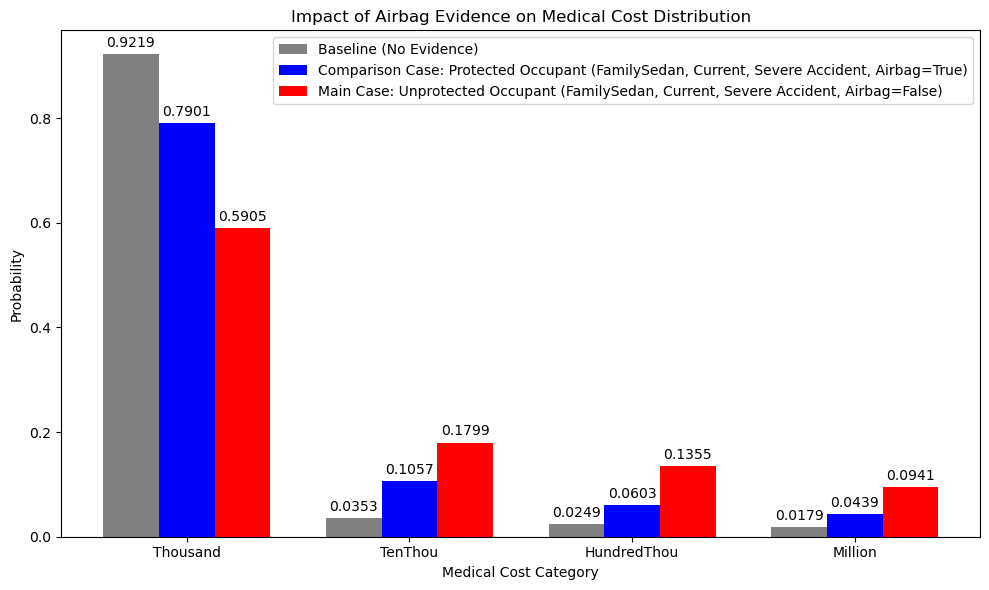

In [102]:
# Extract category names and probability values
categories = result_s1_baseline.state_names['MedCost']
baseline = result_s1_baseline.values
protected = result_s1_protected.values
unprotected = result_s1_unprotected.values

# Set up x-axis positions and bar width
x = np.arange(len(categories))
width = 0.25

# Adjust figure size for better readability
plt.figure(figsize=(10, 6))

# Create grouped bar charts and store their containers
bars1 = plt.bar(x - width, baseline, width, label='Baseline (No Evidence)', color='gray')
bars2 = plt.bar(x, protected, width, label='Comparison Case: Protected Occupant (FamilySedan, Current, Severe Accident, Airbag=True)', color='blue')
bars3 = plt.bar(x + width, unprotected, width, label='Main Case: Unprotected Occupant (FamilySedan, Current, Severe Accident, Airbag=False)', color='red')

# Add exact probability values on top of each bar (4 decimal places)
plt.bar_label(bars1, fmt='%.4f', padding=3)
plt.bar_label(bars2, fmt='%.4f', padding=3)
plt.bar_label(bars3, fmt='%.4f', padding=3)

# Set labels, title, and x-ticks
plt.xticks(x, categories)
plt.xlabel("Medical Cost Category")
plt.ylabel("Probability")
plt.title("Impact of Airbag Evidence on Medical Cost Distribution")

# Display legend
plt.legend()

# Ensure elements fit perfectly within the figure margins
plt.tight_layout()

# Display the plot
plt.show()

### Analysis and Comparison
**Analysis of Updated Probabilities**  

The results show a clear increase in medical cost risk when evidence is added.

In the baseline case (without evidence), the probability of the highest medical cost category (`Million`) is only 0.0179. However, in the Unprotected Occupant case, this probability increases to 0.0941. This represents more than a **fivefold increase** in extreme medical cost risk. A similar pattern appears in the medium cost categories. The probability of `TenThou` increases from 0.0353 (baseline) to 0.1799 (Unprotected), which is more than **five times higher**. The probability of `HundredThou` increases from 0.0249 (baseline) to 0.1355 (Unprotected), also more than **five times higher** than the baseline level.

Even when compared to Protected Occupant case, the absence of airbags substantially increases risk. For example, `Million` increases from 0.0439 (Protected) to 0.0941 (Unprotected), which is more than **double**. Similarly, `HundredThou` increases from 0.0603 (Protected) to 0.1355 (Unprotected).

At the same time, the probability of the lowest category (`Thousand`) decreases significantly from 0.9219 (baseline) to 0.5905 in (Unprotected). This clearly shows that probability mass shifts away from low-cost outcomes toward medium and high-cost outcomes.

Overall, the evidence does not just slightly increase risk. It clearly shifts the distribution toward higher medical cost exposure.

**Critical Evaluation of Evidence Impact**  

The evidence changes the network step by step. When `Airbag = False`, it affects `Cushioning`, which then affects `MedCost`. Combined with `Accident = Severe`, this creates a compounded effect that increases financial risk exposure.

Although the MAP result shows that `Thousand` remains the most probable single outcome, the marginal probabilities reveal a substantial increase in higher-cost categories. This means looking only at the most likely outcome can hide the real risk.

From a risk management perspective, the marginal distribution provides a more informative view because it captures all possible outcomes. For insurance pricing and financial planning, understanding the increase in high-cost categories (e.g., `HundredThou` and `Million`) is more important than knowing only the most likely category.

**Limitations of the Analysis**  

Although the analysis provides useful insights, it also has several limitations. First, the `Airbag` node is used as a proxy for seat-level protection, since the model does not explicitly include a seating position variable. This simplification may not fully represent real passenger-level risk differences.

Second, the modified CPDs are based on reasonable assumptions rather than real empirical accident data from Indonesia. Therefore, the numerical results should be interpreted as scenario-based simulations rather than precise real-world predictions.

Third, the model does not include other external factors such as road conditions, traffic density, or regional accident patterns, which could further influence medical cost outcomes.

Therefore, the results should be seen as scenario analysis, not exact real-world predictions.

### **Scenario 2: Urban Theft Risk Exposure from Promotional Economy Cars with Free Insurance**

### Defining The Scenario  

**Target Node:** `Theft`  
**Evidence Nodes:**

* `HomeBase`: **City**
* `VehicleYear`: **Current**
* `MakeModel`: **Economy**

**Research Question:**
To what extent does owning a brand-new economy car in a city environment increase theft risk exposure for insurers?


**Justification:**
In Indonesia, economy cars are frequently promoted by dealerships through attractive campaigns, including low down payments and free insurance packages. For example, during the ongoing Ramadan promotion in 2026, dealers such as **[Auto2000](https://auto2000.co.id/promosi/mobil-baru/promo-ramadan-agya---berkah-maxeasymal)** offer one year of free insurance for new economy models such as the Toyota Agya. These promotions significantly increase the number of newly registered economy vehicles within a short period.

While economy cars are not luxury assets, their high market volume and liquidity may create different types of theft exposure. A brand-new `Economy` vehicle (`VehicleYear = Current`) located in a `City` environment may face increased theft risk due to:

* High sales volume
* Strong resale demand for spare parts
* Rapid growth of similar models in urban areas

When dealers bundle free insurance with new economy cars, insurers may face aggregate exposure if theft probability is underestimated. This scenario evaluates whether a newly purchased economy vehicle in an urban setting carries theft risk above the network’s baseline probability.

To demonstrate this risk disparity, we compare the `Theft`   probabilities between:  

* Main Case: Urban Economy (New Economy Car in the City)  `HomeBase=City`, `VehicleYear=Current`, `MakeModel=Economy`.
* Comparison Case 1: Isolate City Effect (HomeBase=Suburb) **`HomeBase=Suburb`**, `VehicleYear=Current`, `MakeModel=Economy`
* Comparison Case 2: Isolate New Car Effect (VehicleYear=Older) `HomeBase=City`, **`VehicleYear=Older`**, `MakeModel=Economy`

This analysis is important for insurers to assess whether promotional partnerships with dealerships may unintentionally increase claim frequency in the short term.  

**Model Setup**

In [105]:
# Reload the original model for Scenario 2
model_s2 = bif_reader.get_model()

### CPD Modification for Scenario 2  

**No CPD modification is required for Scenario 2**. The original model already reflects higher theft risk in urban areas.  

For example, for mid-value vehicles (`TenThou`), the theft probability in `City` is 0.005, compared to 0.0002 in `Suburb` and 0.0001 in `Rural`. This shows that urban theft risk is already significantly higher in the existing CPD.  

In addition, `MakeModel` affects `Theft` indirectly through `CarValue`, and `VehicleYear` is already defined probabilistically in the model. Therefore, modifying the CPDs is not necessary for this scenario.  

### Perform Inference  

Inference is performed to analyze the probability of `Theft` under different conditions. 

**Baseline Analysis (Without Evidence)**  

In [108]:
# Initialize inference engine for Scenario 2
infer_s2 = VariableElimination(model_s2)

# Compute the prior marginal/baseline probability of Theft (no evidence)
result_s2_baseline = infer_s2.query(
    variables=['Theft'],
    elimination_order='MinFill'
)

print("--- Marginal Probability of Theft (No Evidence) ---")
print(result_s2_baseline)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

--- Marginal Probability of Theft (No Evidence) ---
+--------------+--------------+
| Theft        |   phi(Theft) |
+==============+==============+
| Theft(True)  |       0.0012 |
+--------------+--------------+
| Theft(False) |       0.9988 |
+--------------+--------------+


**Main Case: Urban Economy (New Economy Car in the City)**  

In [110]:
print("--- URBAN ECONOMY THEFT RISK SIMULATION ---")

# Urban Economy Case
result_s2_urban = infer_s2.query(
    variables=['Theft'],
    evidence={
        'HomeBase': 'City',
        'VehicleYear': 'Current',
        'MakeModel': 'Economy'
    },
    elimination_order='MinFill'
)

print("\n[URBAN ECONOMY CASE (City, Current, Economy)]")
print(result_s2_urban)

--- URBAN ECONOMY THEFT RISK SIMULATION ---


  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]


[URBAN ECONOMY CASE (City, Current, Economy)]
+--------------+--------------+
| Theft        |   phi(Theft) |
+==============+==============+
| Theft(True)  |       0.0043 |
+--------------+--------------+
| Theft(False) |       0.9957 |
+--------------+--------------+


**Comparison Case 1: Isolate City Effect (HomeBase=Suburb)**  

In [112]:
# Comparison Case: Suburban Economy Vehicle
result_s2_suburb = infer_s2.query(
    variables=['Theft'],
    evidence={
        'HomeBase': 'Suburb',
        'VehicleYear': 'Current',
        'MakeModel': 'Economy'
    },
    elimination_order='MinFill'
)

print("\n[COMPARISON CASE 1 (Suburb, Current, Economy)]")
print(result_s2_suburb)

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]


[COMPARISON CASE 1 (Suburb, Current, Economy)]
+--------------+--------------+
| Theft        |   phi(Theft) |
+==============+==============+
| Theft(True)  |       0.0002 |
+--------------+--------------+
| Theft(False) |       0.9998 |
+--------------+--------------+


**Comparison Case 2: Isolate New Car Effect (VehicleYear=Older)**  

In [114]:
# Comparison Case 2: Older Economy Vehicle in City
result_s2_older = infer_s2.query(
    variables=['Theft'],
    evidence={
        'HomeBase': 'City',
        'VehicleYear': 'Older',
        'MakeModel': 'Economy'
    },
    elimination_order='MinFill'
)

print("\n[COMPARISON CASE 2 (City, Older, Economy)]")
print(result_s2_older)


  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]


[COMPARISON CASE 2 (City, Older, Economy)]
+--------------+--------------+
| Theft        |   phi(Theft) |
+==============+==============+
| Theft(True)  |       0.0015 |
+--------------+--------------+
| Theft(False) |       0.9985 |
+--------------+--------------+


**Interpretation of Results**  

In the baseline case (without evidence), the overall probability of theft in the network is relatively low (0.0012). This reflects the average theft risk across all vehicle types, locations, and vehicle ages.

In the **Urban Economy Case** (`City`, `Current`, `Economy`), the probability of theft is 0.0043. This is approximately 3.6 times higher than the baseline probability (0.0043 vs 0.0012). This indicates that a brand-new economy vehicle located in an urban environment carries substantially higher theft risk than the average vehicle in the network.

When we isolate the location effect in **Comparison Case 1** (`Suburb`, `Current`, `Economy`), the theft probability drops significantly to 0.0002. This means that a new economy vehicle in a city is more than **21 times** riskier than the same vehicle in a suburban area (0.0043 vs 0.0002). This confirms that urban location is a major driver of theft risk in the model.

When we isolate the vehicle age effect in **Comparison Case 2** (`City`, `Older`, `Economy`), the theft probability decreases to 0.0015. This shows that a new vehicle in a city is almost **three times** more likely to be stolen than an older vehicle in the same urban environment (0.0043 vs 0.0015). Therefore, vehicle newness also contributes significantly to theft risk.

Overall, the combination of two factors (**urban location** and **brand-new vehicle status**) substantially increases theft probability.

**From an insurance perspective, promotional campaigns that offer free insurance for new economy cars in cities may unintentionally increase aggregate exposure**. Even though the absolute probability of theft remains relatively small, the risk increases by more than twenty times compared to suburban conditions and nearly three times compared to older vehicles in the same city. This suggests that free insurance promotions for new economy vehicles in urban areas may lead to higher claim frequency than expected if theft risk is not carefully priced.

**Elimination Ordering**  

The elimination order is determined using the MinFill heuristic.  

In [117]:
# Define the evidence nodes used in Scenario 2
evidence_nodes_s2 = ['HomeBase', 'VehicleYear', 'MakeModel']

# Identify all variables to eliminate
# all nodes except the target 'Theft' and the evidence nodes
# Sort the list first so the output is consistent every time the code is run
nodes_to_eliminate_s2 = sorted(list( 
    set(model_s2.nodes()) - set(['Theft']) - set(evidence_nodes_s2)
))

# Use the MinFill heuristic to compute the elimination order
heuristic_s2 = MinFill(model_s2)
order_s2 = heuristic_s2.get_elimination_order(nodes_to_eliminate_s2)

print("Elimination Ordering for Scenario 2 (MinFill):", order_s2)

  0%|          | 0/23 [00:00<?, ?it/s]

Elimination Ordering for Scenario 2 (MinFill): ['DrivHist', 'DrivQuality', 'PropCost', 'DrivingSkill', 'ThisCarCost', 'CarValue', 'Mileage', 'ILiCost', 'OtherCarCost', 'SeniorTrain', 'AntiTheft', 'GoodStudent', 'MedCost', 'Accident', 'Antilock', 'Cushioning', 'RuggedAuto', 'Airbag', 'ThisCarDam', 'OtherCar', 'Age', 'RiskAversion', 'SocioEcon']


**Elimination Ordering and Justification**

Using the MinFill heuristic, the algorithm removes variables step by step before calculating the final probability of Theft. The order is chosen to make the computation more efficient.

In this case, `ILiCost` and `DrivQuality` are eliminated early in the process. This does not mean they are less important. It simply means that removing them first makes the calculation easier based on the structure of the network.

Variables such as `RiskAversion` and `SocioEcon` are eliminated near the end because removing them earlier would create more new connections between nodes.

The elimination order does not change the final probability result. It only affects how efficiently the computation is performed. By using MinFill, the size of intermediate calculations can be reduced.

**Calculation of Intermediate Factors**  

After determining the elimination order, we now illustrate how an intermediate factor is formed during one elimination step. In the Variable Elimination algorithm, all CPDs are treated as initial factors. Hidden variables are removed one by one, and each removal creates a new intermediate factor.

As an example, consider the elimination of the variable `CarValue`, which directly influences the target node `Theft`.

The relevant factors involving `CarValue` are:

$$P(Theft \mid AntiTheft, HomeBase, CarValue)$$

and

$$P(CarValue \mid MakeModel, VehicleYear, Mileage)$$

When evidence such as `HomeBase = City`, `VehicleYear = Current`, and `MakeModel = Economy` is introduced, the corresponding factors are restricted accordingly.


**Step 1: Factor Multiplication**

The algorithm multiplies the two factors that share the variable `CarValue`:

$$
P(Theft \mid AntiTheft, HomeBase, CarValue)
\cdot
P(CarValue \mid MakeModel, VehicleYear, Mileage)
$$


**Step 2: Summing Out `CarValue`**

The variable `CarValue` is then eliminated by summing over its possible states:

$$\begin{aligned}
\phi_1(Theft, AntiTheft, Mileage) &= \sum_{CarValue} P(Theft \mid AntiTheft, HomeBase = City, CarValue) \\
&\quad \cdot P(CarValue \mid MakeModel = Economy, VehicleYear = Current, Mileage)
\end{aligned}$$

The resulting function $\phi_1$ is an **intermediate factor**, because it is created during elimination and does not exist in the original CPDs.

This process continues for other hidden variables according to the elimination order until only the target variable `Theft` remains. The final factor corresponds to the probability distribution of `Theft` under the given evidence.  

The calculation for this intermediate factor is as follows:

In [120]:
# Extract initial CPDs and convert them to discrete factors
factor_theft = model_s2.get_cpds('Theft').to_factor()
factor_carvalue = model_s2.get_cpds('CarValue').to_factor()

# Apply evidence for Scenario 2 (City, Current, Economy)
factor_theft.reduce([('HomeBase', 'City')])
factor_carvalue.reduce([('MakeModel', 'Economy'), ('VehicleYear', 'Current')])

# Step 1: Factor Multiplication
factor_product = factor_theft * factor_carvalue

# Step 2: Summing Out (Marginalize) the hidden variable 'CarValue'
phi_1_s2 = factor_product.marginalize(['CarValue'], inplace=False)

# Display the resulting intermediate factor
print("Intermediate Factor phi_1 (After eliminating CarValue):")
print(phi_1_s2)

Intermediate Factor phi_1 (After eliminating CarValue):
+---------------------+--------------+------------------+--------------------------------+
| Mileage             | Theft        | AntiTheft        |   phi(Mileage,Theft,AntiTheft) |
+=====================+==============+==================+================================+
| Mileage(FiveThou)   | Theft(True)  | AntiTheft(True)  |                         0.0022 |
+---------------------+--------------+------------------+--------------------------------+
| Mileage(FiveThou)   | Theft(True)  | AntiTheft(False) |                         0.0051 |
+---------------------+--------------+------------------+--------------------------------+
| Mileage(FiveThou)   | Theft(False) | AntiTheft(True)  |                         0.9979 |
+---------------------+--------------+------------------+--------------------------------+
| Mileage(FiveThou)   | Theft(False) | AntiTheft(False) |                         0.9949 |
+---------------------+-----------

**The Most Probable Explanation Given the Evidence**  

MAP inference is used to determine the most probable outcome of `MedCost` given the evidence.

In [122]:
# MAP inference for Urban Economy Case
map_s2_urban = infer_s2.map_query(
    variables=['Theft'],
    evidence={
        'HomeBase': 'City',
        'VehicleYear': 'Current',
        'MakeModel': 'Economy'
    },
    elimination_order='MinFill'
)

print("MAP Result: Urban Economy (City, Current, Economy):")
print(map_s2_urban)

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

MAP Result: Urban Economy (City, Current, Economy):
{'Theft': 'False'}


In [123]:
# MAP inference for Comparison Case 1 (Suburb)
map_s2_suburb = infer_s2.map_query(
    variables=['Theft'],
    evidence={
        'HomeBase': 'Suburb',
        'VehicleYear': 'Current',
        'MakeModel': 'Economy'
    },
    elimination_order='MinFill'
)

print("\nMAP Result: Comparison Case 1 (Suburb, Current, Economy):")
print(map_s2_suburb)

  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]


MAP Result: Comparison Case 1 (Suburb, Current, Economy):
{'Theft': 'False'}


In [124]:
# MAP inference for Comparison Case 2 (Older Vehicle in City)
map_s2_older = infer_s2.map_query(
    variables=['Theft'],
    evidence={
        'HomeBase': 'City',
        'VehicleYear': 'Older',
        'MakeModel': 'Economy'
    },
    elimination_order='MinFill'
)

print("\nMAP Result: Comparison Case 2 (City, Older, Economy):")
print(map_s2_older)


  0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]


MAP Result: Comparison Case 2 (City, Older, Economy):
{'Theft': 'False'}


**Comparison with Marginal Probability Results**  

The MAP inference shows that the most probable outcome for `Theft` is `False` in all three conditions: the Main Case (Urban Economy), Comparison Case 1 (Suburb), and Comparison Case 2 (Older Vehicle in City). This means that, in every scenario, vehicle theft remains less likely than non-theft.

However, the marginal probability distribution provides a more detailed perspective. While `Theft = False` remains the most likely single outcome, the probability of `Theft = True` increases substantially under specific risk conditions. In the Urban Economy case, the theft probability rises to 0.0043, which is approximately **3.6 times higher than the baseline** or no evidence (0.0012), more than **21 times higher than the suburban case** (0.0002), and nearly **three times higher than the older vehicle case** in the same city (0.0015).

This demonstrates an important difference between MAP and marginal inference. MAP identifies only the most likely category and does not reflect changes in risk magnitude. In contrast, marginal probabilities reveal how theft risk increases significantly when urban location and new vehicle status are combined.

For insurance risk assessment, marginal inference is therefore more informative, as it captures meaningful changes in risk exposure even when the most probable outcome remains unchanged.

**Differences in Insights Gained from Each Method**  

The two inference methods provide different types of insights. MAP focuses only on the single most probable outcome. In this scenario, MAP indicates that `Theft = False` remains the most likely result in all conditions. This is useful for identifying the dominant outcome, but it does not show how risk levels change under different circumstances.

In contrast, marginal inference provides the full probability distribution of `Theft`. Although `Theft = False` remains the most likely outcome, the probability of `Theft = True` increases significantly in the urban and new vehicle conditions. This reveals meaningful changes in theft risk that MAP alone does not capture.

For insurance risk assessment, marginal inference is more informative because it highlights relative increases in theft probability. Even when theft is still unlikely in absolute terms, a multiple-fold increase in probability can have a substantial impact on aggregate claims, especially when many vehicles are insured under promotional programs.

**Influence of Evidence on Target Node Probabilities (Graph)**  

The following graph shows how the probabilities change under different conditions.

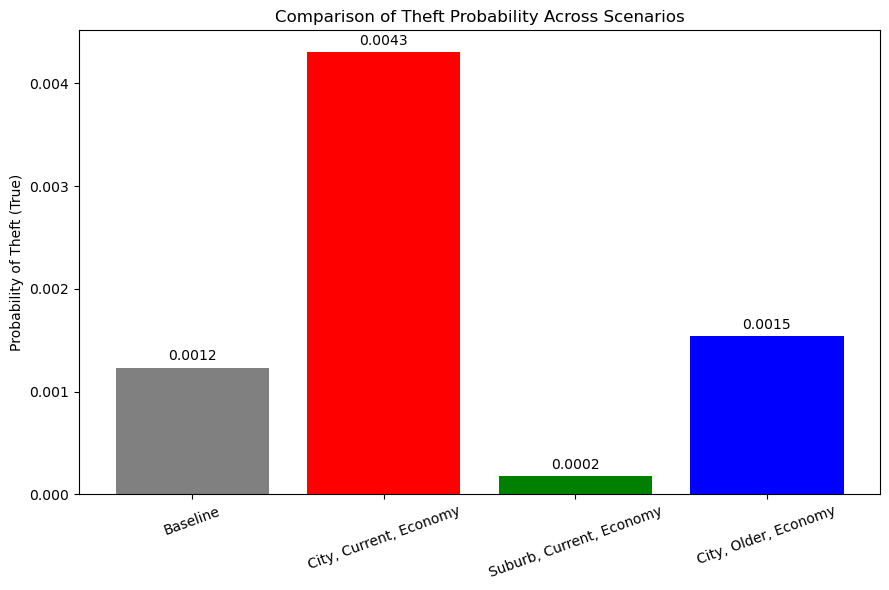

In [127]:
# Define scenario labels
labels = ['Baseline',
          'City, Current, Economy',
          'Suburb, Current, Economy',
          'City, Older, Economy']

# Extract Theft(True) probabilities for each scenario
theft_true_values = [
    result_s2_baseline.values[0],
    result_s2_urban.values[0],
    result_s2_suburb.values[0],
    result_s2_older.values[0]
]

# Adjust figure size for better readability
plt.figure(figsize=(9, 6))

# Create bar chart and store the bar container
bars = plt.bar(labels, theft_true_values, color=['gray', 'red', 'green', 'blue'])

# Set labels and title
plt.ylabel("Probability of Theft (True)")
plt.title("Comparison of Theft Probability Across Scenarios")
plt.xticks(rotation=20)

# Add exact probability values on top of each bar (4 decimal places)
plt.bar_label(bars, fmt='%.4f', padding=3)

# Ensure rotated labels fit perfectly within the figure margins
plt.tight_layout() 

# Display the plot
plt.show()

### Analysis and Comparison
**Analysis of Updated Probabilities**  

The updated probabilities show a clear and measurable increase in theft risk when specific urban and vehicle-related conditions are introduced.

In the baseline case (without evidence), the probability of theft is 0.0012. However, in the Urban Economy case (`City`, `Current`, `Economy`), the probability increases to 0.0043. This represents approximately a **3.6-fold increase** compared to the baseline level.

When we isolate the location effect, the probability of theft in the suburban case (`Suburb`, `Current`, `Economy`) is only 0.0002. This means that a new economy vehicle in a city is more than **21 times** more likely to be stolen than the same vehicle in a suburban area (0.0043 vs 0.0002). This confirms that urban location is a dominant risk factor in the model.

When we isolate the vehicle age effect, the probability of theft for an older economy vehicle in the city (`City`, `Older`, `Economy`) is 0.0015. This shows that a new vehicle in a city is almost **three times** more likely to be stolen than an older vehicle in the same location (0.0043 vs 0.0015).

In summary, the combination of two factors (**urban location** and **brand-new vehicle status**) significantly increases theft probability relative to the network average.


**Critical Evaluation of Evidence Impact**  

The results illustrate how evidence propagates through the Bayesian Network structure. The variable `MakeModel` influences `CarValue`, which directly affects `Theft`, while `HomeBase` directly modifies theft risk based on geographical exposure. When `VehicleYear = Current` is combined with `HomeBase = City`, the effects compound, leading to a noticeable increase in theft probability.

Although the MAP results indicate that `Theft = False` remains the most probable outcome in all scenarios, the marginal probabilities reveal substantial relative increases in theft risk. This highlights an important insight: focusing only on the most likely outcome can obscure meaningful changes in risk magnitude.

From an insurance perspective, even small absolute increases in theft probability can significantly impact aggregate claims when many vehicles are insured under promotional programs. Therefore, marginal inference provides a more informative measure of exposure than MAP alone.


**Limitations of the Analysis**  

Despite these findings, several limitations must be acknowledged. First, the model assumes that theft probability is determined solely by structural relationships within the network and does not account for real-time market dynamics, such as sudden spikes in crime rates or seasonal variations.

Second, the promotional effect of “free insurance” is not explicitly modeled as a change in theft probability. Instead, the analysis assumes that promotions increase the number of exposed vehicles rather than altering individual theft likelihood.

Third, the model does not incorporate external factors such as law enforcement intensity, neighborhood-level crime data, or economic fluctuations, which could further influence theft risk.

Therefore, while the Bayesian Network provides useful insights into how urban concentration and vehicle newness affect theft probability, the results should be interpreted as structured scenario analysis rather than exact real-world forecasts.

**References**:  

* Auto2000. (n.d.). Promo Ramadan Agya – Berkah MaxEasyMal. Retrieved February 17, 2026, from https://auto2000.co.id/promosi/mobil-baru/promo-ramadan-agya---berkah-maxeasymal
* Zurich General Insurance Indonesia. (n.d.). Asuransi mobil Autocillin. Retrieved February 17, 2026, from https://www.zurich.co.id/produk-asuransi/untuk-kendaraan/asuransi-mobil-autocillin

# **Part B. Financial Event Classification Using Conditional Random Fields**

## Task 1: Data Preaparation and Pre-processing

Import the necessary library and files.

In [133]:
# Import the packages
import numpy as np
import pandas as pd              # Import pandas
import os                        # acces to files if necessary
import matplotlib.pyplot as plt  # for graphics
import math
import random

# Define the file path for train data
file_path = "financial_train.csv"

# Load the dataset
try:
    # Reading the CSV file into a pandas DataFrame
    financial_data = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print(financial_data.head())  # Display the first few rows of the dataset
except FileNotFoundError:
    print(f"Error: File not found at {file_path}. Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")

Dataset loaded successfully!
  Token  POS  IsNumeric          Label  DocID  PrevToken     NextToken
0  Visa  NNP      False     B-EARNINGS    447        NaN          beat
1  with   DT      False              O    486        NaN           NaN
2    by   IN      False        I-STOCK    726  increased  $5.2 billion
3    to   IN      False  I-ACQUISITION    978      talks       acquire
4    of   IN      False     I-EARNINGS    160    revenue  $5.2 billion


Next is to import the test data.

In [135]:
# Define the file path for train data
file_path = "financial_test.csv"

# Load the dataset
try:
    # Reading the CSV file into a pandas DataFrame
    financial_data_test = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print(financial_data_test.head())  # Display the first few rows of the dataset
except FileNotFoundError:
    print(f"Error: File not found at {file_path}. Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")

Dataset loaded successfully!
           Token POS  IsNumeric       Label  DocID  PrevToken NextToken
0  $15.7 billion  CD       True  I-EARNINGS    769       with       NaN
1   $3.1 billion  CD       True  I-EARNINGS    723       with       NaN
2          stock  IN      False     I-STOCK    838  Citigroup     price
3             or  DT      False           O    979        NaN       NaN
4             on  DT      False           O    277        NaN       NaN


Next is to check the shape of the train dataframe.

In [137]:
financial_data.shape

(30000, 7)

Next is to check whether there are null values in the dataset.

In [139]:
financial_data.isna().sum()

Token            0
POS              0
IsNumeric        0
Label            0
DocID            0
PrevToken    13270
NextToken    13270
dtype: int64

The null values are only in the `PrevToken` and `NextToken` columns. This is intended since the token could be at the start of the sentence or at the end. Next is to check the `labels` and `Part-of-Speech` tags.

In [141]:
print(financial_data['Label'].value_counts())
print(financial_data['POS'].value_counts())

Label
O                9670
I-MERGER         4863
I-EARNINGS       4666
I-ACQUISITION    3777
I-STOCK          3424
B-EARNINGS        900
B-STOCK           900
B-ACQUISITION     900
B-MERGER          900
Name: count, dtype: int64
POS
IN     12209
DT      9670
NNP     5400
CD      1800
VBD      921
Name: count, dtype: int64


There are 5 types of token label: Merger, Earnings, Acquisition, Stock and Others (O). The definition of each labels can be seen below:

|Label|Definition|
|-----|----------|
|B-EARNINGS|Beginning of an earnings report event|
|I-EARNINGS|Continuation of an earnings report event|
|B-STOCK|Beginning of a stock price change event|
|I-STOCK|Continuation of a stock price change event|
|B-ACQUISITION|Beginning of an acquisition event|
|I-ACQUISITION|Continuation of an acquisition event|
|B-MERGER|Beginning of a merger event|
|I-MERGER|Continuation of a merger event|
|O|Non-event tokens|

And the Part-of-Speech tag definition is as follows:

|PoS Tag|Definition|
|-----|----------|
|IN|Preposition|
|DT|Determiner|
|NNP|Proper Noun|
|CD|Cardinal Number|
|VBD|BVerb, Past-tense|

Looking at the `value_counts` result for the `labels`, `Other` tokens are the most abundant in the dataset with 9670, followed by `I-Merger` with 4863. The rest of `Continuation` tokens closely follow `I-Merger` in the following order: `Earnings`, `Acquisition` and `Stock`. All `Beginning` tokens have the same amount with 900. One insight from this fact is to include more **merger** specific keywords in the Feature Engineering task up next.

## Task 2: Feature Engineering

Import the necessary pacakges for this task.

In [149]:
import nltk
from nltk.util import ngrams
from IPython.display import display  # Import for displaying DataFrame in Jupyter Notebook

Set the financial events keywords.

In [151]:
finance_keywords_v0 = {
    "merge", "merged", "merger", "consolidation", "amalgamation", "tie-up", "combination",  # Merger key words
    "acquire", "acquired", "acquisition", "buyout", "takeover", "purchased", "deal", "bid", # Acquisition keywords
    "earnings", "revenue", "profit", "guidance", "results", "forecast", "quarterly",        # Earnings keuwords
    "shares", "stock", "rose", "fell", "up", "down", "plunged", "surged", "stock", "price"     # Stock Keywords
}

The initial (version 0) of the financial keywords are set. Next is to extract the features. This is done by creating a function that extracts the content of the row whilst checking if the tokens are included in the set of keywords created above. In addition, Bigrams and Trigrams are added to include the local context of the data. This addition is done through the following logic

- Bigrams = `Token` + `NextToken`
- Trigrams = `PrevToken` + `Token` + `NextToken`

Doing so, the global order of the data set don't need to be reset to account for the scrambled `DocID`. In addition, the `DocID` will not be included in the feature selection since it does not provide any information regardiang the event and it could cause data leakage.

In [153]:
def extract_features_initial(df,keywords):
    features = []

    for i in range(len(df)):
        # Set the row
        row = df.iloc[i]

        # get the feature of the token
        token = row["Token"]
        docid = row["DocID"]
        label = row["Label"]
        pos = row["POS"]
        is_numeric = row["IsNumeric"]

        # Get the local context of the token
        local_prev_token = "" if pd.isna(row["PrevToken"]) else row["PrevToken"]
        local_next_token = "" if pd.isna(row["NextToken"]) else row["NextToken"]

        # get the token info in the current order of the dataset
        prev_token = row["PrevToken"] if i > 0 else "<START>"
        next_token = row["NextToken"] if i < len(df)-1 else "<END>"

        # get the PoS info in the current order of the dataset
        prev_pos = df.iloc[i-1]["POS"] if i > 0 else "<START>"
        next_pos = df.iloc[i+1]["POS"] if i < len(df)-1 else "<END>"
        
        # Create the bigrams and trigrams utlising the logic mentioned previously
        bigram = f"{token} {local_next_token}"
        trigram = f"{local_prev_token} {token} {local_next_token}"
        
        token_features = {
            "Token": token,
            "DocID": docid,
            "Label": label,
            "POS": pos,
            "IsNumeric": is_numeric,
            "PrevToken": prev_token,
            "NextToken": next_token,
            "PrevPOS": prev_pos,
            "NextPOS": next_pos,
            
            # NEW n-gram-like features
            "Bigram": bigram,
            "Trigram": trigram,
            
            # keyword feature
            "IsFinanceKeyword": token.lower() in keywords,
        }
        features.append(token_features)

    return pd.DataFrame(features)

The function is created. Next is to perform the feature extraction. The function allows the keywords set to be selected. This is done for ease of iteration should any new keywords are added into the set (v1 and so on).

In [155]:
# Extract features
features_df_v0 = extract_features_initial(financial_data,      # Set the data
                                          finance_keywords_v0) # set the keywords set

# check the features data frame
features_df_v0.head()

,Token,DocID,Label,POS,IsNumeric,PrevToken,NextToken,PrevPOS,NextPOS,Bigram,Trigram,IsFinanceKeyword
0,Visa,447,B-EARNINGS,NNP,False,<START>,beat,<START>,DT,Visa beat,Visa beat,False
1,with,486,O,DT,False,NaN,NaN,NNP,IN,with,with,False
2,by,726,I-STOCK,IN,False,increased,$5.2 billion,DT,IN,by $5.2 billion,increased by $5.2 billion,False
3,to,978,I-ACQUISITION,IN,False,talks,acquire,IN,IN,to acquire,talks to acquire,False
4,of,160,I-EARNINGS,IN,False,revenue,$5.2 billion,IN,DT,of $5.2 billion,revenue of $5.2 billion,False


For training purposes, the features data are stored into another csv file.

In [157]:
# Save the feature data frame into another file
output_path = "FinanceFeatures_Train.csv"
features_df_v0.to_csv(output_path, index=False)

The feature dataframe is created. Next is to check whether the Finance keywords dictionary created is precise enough. This is done by checking the number of `True` or `False` tag in the `IsFinanceKeyword` column.

In [159]:
# Check using value_counts method.
v0_true_ratio = round(features_df_v0[features_df_v0['IsFinanceKeyword']==True]['IsFinanceKeyword'].sum()/len(features_df_v0),4)
print(features_df_v0['IsFinanceKeyword'].value_counts())
print('\n')
print(f'Ratio of Caught Finance keyword: {round(v0_true_ratio*100,2)}%')

IsFinanceKeyword
False    25488
True      4512
Name: count, dtype: int64


Ratio of Caught Finance keyword: 15.04%


The finance keywords provided catch 15.04% of the total token. This is ideal since the keywords manage to discriminate the 'Event trigger' tokens without introducing noise. Therefore, proceed with the next step using the provided Keywords.

The preparation for the model training is complete. Proceed to the next task.

## Task 3: Model Training

The first step is to install the CRF suite package from sklearn

In [163]:
# Commented post instalation
# !pip install sklearn-crfsuite

Next is to create a function that turn the features in the `feature_df_v0` dataframe into dictionary. In this process, some noise will also be introduced into the dataset. Random noise features were incorporated following the tutorial implementation to simulate feature variability and demonstrate model robustness. For reproducability, the seed is set globally.

In [165]:
# Import the necessary packages and functions
from sklearn_crfsuite import CRF
from sklearn_crfsuite import metrics
from sklearn_crfsuite.metrics import flat_f1_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from itertools import chain
import scipy.stats


# Create the function
def extract_features(token, pos, prev_token, next_token,
                    prev_pos, next_pos, bigram, trigram, is_finance_keyword):
    """Extract features for a single token"""
    np.random.seed(666)
    random.seed(666)

    features = {
        'token.lower': token.lower(),
        'token.isupper': token.isupper(),
        'token.istitle': token.istitle(),
        'pos': pos,
        'prev_token': prev_token,
        'next_token': next_token,
        'prev_pos': prev_pos,
        'next_pos': next_pos,
        'bigram': bigram,
        'trigram': trigram,
        'is_finance_keyword': is_finance_keyword,

        # Simplified combination features to reduce overfitting
        'token+pos': f'{token.lower()}_{pos}'
    }

    # Add some noise to features randomly
    if np.random.random() < 0.1:  # 10% chance to add noise
        features['random_noise'] = np.random.random()

    return features

Next step is to create a function that create sequences to be put into the CRF training. The `extract_features` function will be put inside this function to prepare the sequences. Here, the `window size` is set as 1 since only the previous and next tokens are taken into consideration in the form of `PrevToken` and `NextToken`. For the iteration process, the token will be grouped by their own `DocID`. This is done to avoid a problem where the sequences contain only 1 token. This is particularly bad since the classifier has become a ***Singular Token Classifier***, and the 

In [167]:
def prepare_sequences(data):
    """Prepare sequences for CRF training"""
    sequences = []
    labels = []
    dropout_rate = 0.05
    np.random.seed(666)
    random.seed(666)

    for doc_id, group in data.groupby("DocID", sort=False):
        current_sequence = []
        current_labels = []

        for _, row in group.iterrows():
            if np.random.random() > dropout_rate:

                features = extract_features(
                    row['Token'], row['POS'], 
                    row['PrevToken'], row['NextToken'],
                    row['PrevPOS'], row['NextPOS'],
                    row['Bigram'], row['Trigram'],
                    row['IsFinanceKeyword']
                )
                current_sequence.append(features)
                current_labels.append(row['Label'])

        if current_sequence:
            sequences.append(current_sequence)
            labels.append(current_labels)

    return sequences, labels

Next is to prepare the CRF training function. For the following function, the hyperparameters (`c1` and `c2`) are not tuned yet. This is done to see the **Stock** performance of the CRF function. The scoring is done using flat F1 score, which is more suitable for CRF.

In [169]:
from sklearn.metrics import make_scorer
from sklearn_crfsuite.metrics import flat_f1_score

# Create the appropriate scorer
crf_scorer = make_scorer(flat_f1_score, average='weighted')

def train_crf(X_train, y_train):
    """Train CRF model with randomised search for best parameters tuning"""
    crf = CRF(
        algorithm='lbfgs',
        max_iterations=100,
        all_possible_transitions=True
    )

    # Modified parameter space for less aggressive regularization
    params_space = {
        'c1': scipy.stats.expon(scale=0.1),  # L1 regularization
        'c2': scipy.stats.expon(scale=0.1),  # L2 regularization
        'max_iterations': [50, 100, 150]
    }

    # Use random search for the best parameters
    rs = RandomizedSearchCV(
        crf,
        params_space,
        cv=3,
        verbose=1,
        n_jobs=-1,
        n_iter=15,  # Reduced number of iterations
        scoring=crf_scorer,
        random_state=666   # Add seed
    )

    rs.fit(X_train, y_train)

    return rs.best_estimator_, rs.best_params_

Next is to prepare the evaluation function. In this function, the report is created using the stock `classification_report` function. In addition, a helper function to flatten sequences is also created. This helper function is to be used for creating the Confusion Matrix. Since CRF input is sequecnce and confusion matrix expect flat labels, the sequences must be flattened.

In [171]:
def evaluate_model(model, X_test, y_test):
    """Evaluate the CRF model"""
    y_pred = model.predict(X_test)

    f1 = flat_f1_score(y_test, y_pred, average='weighted')

    y_test_flat = [item for sublist in y_test for item in sublist]
    y_pred_flat = [item for sublist in y_pred for item in sublist]

    report = classification_report(y_test_flat, y_pred_flat)

    return f1, report

def flatten_sequences(y_true, y_pred):
    """Flatten list of label sequences into a single list"""
    y_true_flat = list(chain.from_iterable(y_true))
    y_pred_flat = list(chain.from_iterable(y_pred))
    return y_true_flat, y_pred_flat

Finally, the model is to be trained using the functions that have been created. The training is to be done *Internally*, meaning the `train` data is to be split into 70-30 between the training process and the testing process. This means that the actual test data `financial_data_test` is not used.

In [173]:
# --- Global definition of X and y for use across cells ---
print("Loading data for global X, y...")
data = features_df_v0.copy()

print("Preparing sequences for global X, y...")
X, y = prepare_sequences(data)
print("Global X and y are now available.")
# --- End Global definition ---

def main():
    print("\nRunning main() for internal evaluation...")
    # main() will now use the globally defined X and y
    # The split in main is for its own evaluation, separate from any subsequent splits.
    split_idx = int(len(X) * 0.7)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    print("Training model with hyperparameter tuning (within main())...")
    best_model, best_params = train_crf(X_train, y_train)

    print("Evaluating model (within main())...")
    f1_score, classification_rep = evaluate_model(best_model, X_test, y_test)

    # Generate predictions
    print("Generating predictions for confusion matrix...")
    y_pred = best_model.predict(X_test)

    # Flatten sequences
    y_test_flat, y_pred_flat = flatten_sequences(y_test, y_pred)

    # Get unique labels
    labels = sorted(list(set(y_test_flat)))

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_test_flat, y_pred_flat, labels=labels)

    # Create and display confusion matrix DataFrame
    conf_df = pd.DataFrame(
        conf_matrix,
        index=[f'True_{label}' for label in labels],
        columns=[f'Pred_{label}' for label in labels]
    )

    print("\nBest parameters (from main()):", best_params)
    print("\nF1 Score (from main()):", f1_score)
    print("\nClassification Report (from main()):")
    print(classification_rep)

    # Print Confusion Matrix 
    print("\nConfusion Matrix (by label):")
    display(conf_df)

if __name__ == "__main__":
    main()

Loading data for global X, y...
Preparing sequences for global X, y...
Global X and y are now available.

Running main() for internal evaluation...
Training model with hyperparameter tuning (within main())...
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Evaluating model (within main())...
Generating predictions for confusion matrix...

Best parameters (from main()): {'c1': 0.20626201201452848, 'c2': 0.07362576066229047, 'max_iterations': 150}

F1 Score (from main()): 0.9739142585495835

Classification Report (from main()):
               precision    recall  f1-score   support

B-ACQUISITION       0.81      0.78      0.79       220
   B-EARNINGS       0.88      0.91      0.89       186
     B-MERGER       0.75      0.76      0.75       204
      B-STOCK       1.00      1.00      1.00       216
I-ACQUISITION       0.98      0.98      0.98       875
   I-EARNINGS       0.98      0.98      0.98       956
     I-MERGER       0.98      0.99      0.98      1092
      I-STOCK 

,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,171,9,40,0,0,0,0,0,0
True_B-EARNINGS,5,169,12,0,0,0,0,0,0
True_B-MERGER,35,14,155,0,0,0,0,0,0
True_B-STOCK,0,0,0,216,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,858,0,17,0,0
True_I-EARNINGS,0,0,0,0,0,933,0,23,0
True_I-MERGER,0,0,0,0,16,0,1076,0,0
True_I-STOCK,0,0,0,0,0,22,0,802,0
True_O,0,0,0,0,0,0,0,0,2835


The training is complete and the evaluation will be conducted in the following task.

## Task 4: Model Evaluation

The trained Conditional Random Field (CRF) model was evaluated on the held-out test dataset using standard sequence labelling metrics, including precision, recall, F1-score for each event type, overall accuracy, and a confusion matrix for detailed error analysis. The evaluation was conducted at the token level while preserving the BIO labelling structure (B-, I-, O).

### Overall Performance

The CRF model achieved a weighted F1-score of 0.9739 and an overall accuracy of 0.97 on the test dataset, indicating strong predictive performance across the token classification task. The macro-average F1-score of 0.92\3 suggests that the model performs consistently across different event classes, rather than being overly dominated by the majority class (“O”). This is particularly important in token classification datasets where class imbalance between the event and non-event token exists.

The high weighted F1-score demonstrates that the model effectively balances precision and recall while accounting for class imbalance, which aligns with best practices for evaluating sequence labelling models.

### Precision, Recall, and F1-Score by Event Type

A detailed classification report shows that the model performs exceptionally well on most event categories, particularly for inside tokens (I-*) and the non-event class (O).

- I-MERGER (F1 = 0.98) and I-ACQUISITION (F1 = 0.98) achieved near-perfect scores, indicating that the model is highly effective at recognising continuation tokens within financial events.
- I-EARNINGS (F1 = 0.98) and I-STOCK (F1 = 0.97) also demonstrate strong recall and precision, suggesting that contextual sequential features successfully capture event spans.
- The O label (F1 = 1.00) shows perfect classification, which is expected due to the large support (2835 tokens) and clear contextual distinction from event tokens.

However, comparatively lower performance is observed in beginning tags apart from B-STOCK(F1 = 1):

- B-ACQUISITION (F1 = 0.79)
- B-MERGER (F1 = 0.75)

This indicates that the model finds it more challenging to detect the exact start of event spans compared to continuation tokens. This is common behaviour in BIO sequence models since boundary detection requires better contextual understanding than label continuation.

### Confusion Matrix, Error Analysis and Improvement Proposal

The confusion matrix provides deeper insight into the types of misclassifications made by the CRF model. The results show that most errors occur between semantically related event categories rather than between event and non-event tokens. The following are the errors:

- A notable number of B-ACQUISITION tokens (40) were misclassified as B-MERGER
- Some B-MERGER tokens (35) were predicted as B-ACQUISITION
- Some B-EARNINGS classified as B-ACQUISITION and B-MERGER (5 & 12 tokens respecively)
- Minor confusion exists between I-EARNINGS and I-STOCK tokens (22 & 23 tokens respectively)
- Minor confusion between I-MERGER and I-ACQUISITION tokens (16 & 17 tokens respectively) 

These patterns suggest that the model struggles to distinguish between closely related financial event types, likely due to overlapping linguistic patterns and similar contextual cues in financial text. This is particular to MERGER and ACQUISITON since those terms are very common to appear together in the financial world.

Importantly, there are almost no misclassifications into the “O” class for event tokens, indicating that the model rarely fails to detect events entirely. Instead, errors mainly involve incorrect event categorisation, which is a less severe error in token classification tasks. To summarise based on the confusion matrix and classification metrics, the main types of errors include:

- Misclassification between similar event categories (e.g., Acquisition vs Merger)
- Boundary detection errors in B- labels
- Slight confusion between inside tokens of related financial events
- Lower recall for beginning event tokens compared to inside tokens

These findings indicate that the model captures sequential context well but has limited discriminative power when differentiating semantically similar financial events. Therefore, further **model improvement** can be explored through targeted strategies such as class balancing, advanced hyperparameter optimisation, and removal of noise to improve generalisation and boundary detection performance.

## Task 5: Model Improvement

In this task, the primary objective is to improve the performance for classifying boundary classes. But, these improvement must not impact the previously achieved result such as High F1-score and good accuracy. Therefore, the focus in this task is to compare the B-ACQUISITION, B-EARNIGNS, and B-MERGER F1-score between the manually tuned hyperparameter configurations, along with the overall F1-score and the accuracy.

As previously mentioned in Task 4, the following improvements are to be made:

- Class balancing, done by taking less non event tokens randomly
- removal of drop out noise for the event tokens
- Tune the hyperparameters manually (`c1` and `c2`)
- Add validation set

All of these changes will be put into new functions to maintain previous iteration for ease of comparisons later on.

The first step is to perform class balancing. This step requires creating a new function to downsample the O class, which will be used after the in tandem with the modified `prepare_sequence` function. Particularly, the new function is to be used after the train-test data split.

In addition, the `extract_feature` function will have its random noise be removed.

In [185]:
# update extract feature by removing the random noise
def extract_features_v1(token, pos, prev_token, next_token,
                        prev_pos, next_pos, bigram, trigram, is_finance_keyword):
    """Extract features for a single token, removed the noise"""
    features = {
        'token.lower': token.lower(),
        'token.isupper': token.isupper(),
        'token.istitle': token.istitle(),
        'pos': pos,
        'prev_token': prev_token,
        'next_token': next_token,
        'prev_pos': prev_pos,
        'next_pos': next_pos,
        'bigram': bigram,
        'trigram': trigram,
        'is_finance_keyword': is_finance_keyword,

        # Simplified combination features to reduce overfitting
        'token+pos': f'{token.lower()}_{pos}'
    }

    return features

# update the prepare_sequence function to remove the drop out
def prepare_sequences_v1(data):
    """Prepare sequences for CRF training"""
    sequences = []
    labels = []
    np.random.seed(666)
    random.seed(666)

    for doc_id, group in data.groupby("DocID", sort=False):
        current_sequence = []
        current_labels = []

        for _, row in group.iterrows():
            features = extract_features_v1( # use the modified function
                row['Token'], row['POS'], 
                row['PrevToken'], row['NextToken'],
                row['PrevPOS'], row['NextPOS'],
                row['Bigram'], row['Trigram'],
                row['IsFinanceKeyword']
            )
            current_sequence.append(features)
            current_labels.append(row['Label'])

        if current_sequence:
            sequences.append(current_sequence)
            labels.append(current_labels)

    return sequences, labels

# Create the downsampling function
def downsample_non_event_tokens(X_seq, y_seq, dropout_prob=0.35, seed=666):
    '''function to downsample non event token class (O) '''
    np.random.seed(seed)
    X_new = []
    y_new = []

    for features, labels in zip(X_seq, y_seq):
        new_features= []
        new_labels = []
        for f, lab in zip(features, labels):
            # Introduce drop rate only for non event class
            if lab == "O" and np.random.random() > dropout_prob:
                continue
            new_features.append(f)
            new_labels.append(lab)

        if new_features:
            X_new.append(new_features)
            y_new.append(new_labels)

    return X_new, y_new

Since the parameter tuning could be conducted multiple times, one helper function is to be created which is a function to easily create confusion matrix.

In [187]:
# Create print confusion matrix function
def display_confusion_matrix(y_true, y_pred, set_name, labels):
    '''Function to easily create confusion matrix'''
    y_true_flat = list(chain.from_iterable(y_true))
    y_pred_flat = list(chain.from_iterable(y_pred))
    conf_matrix = confusion_matrix(y_true_flat, y_pred_flat, labels=labels)

    conf_df = pd.DataFrame(
        conf_matrix,
        index=[f'True_{label}' for label in labels],
        columns=[f'Pred_{label}' for label in labels]
    )
    print(f"\n=== {set_name} Confusion Matrix ===")
    display(conf_df)

    # Calculate additional metrics
    f1 = flat_f1_score(y_true, y_pred, average='weighted')
    total = len(y_true_flat)
    correct = sum(1 for true, pred in zip(y_true_flat, y_pred_flat) if true == pred)
    accuracy = correct / total

    print(f"\n{set_name} F1-Score : {f1:.4f}")
    print(f"\n{set_name} Overall Accuracy: {accuracy:.4f}")

    # Per-class metrics
    class_metrics = {}
    for label in labels:
        true_pos = sum(1 for true, pred in zip(y_true_flat, y_pred_flat)
                      if true == label and pred == label)
        false_pos = sum(1 for true, pred in zip(y_true_flat, y_pred_flat)
                       if true != label and pred == label)
        false_neg = sum(1 for true, pred in zip(y_true_flat, y_pred_flat)
                       if true == label and pred != label)

        precision = true_pos / (true_pos + false_pos) if (true_pos + false_pos) > 0 else 0
        recall = true_pos / (true_pos + false_neg) if (true_pos + false_neg) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

        class_metrics[label] = {
            'precision': precision,
            'recall': recall,
            'f1-score': f1,
            'support': sum(1 for true in y_true_flat if true == label)
        }

    metrics_df = pd.DataFrame(class_metrics).T
    print(f"\n{set_name} Detailed Class Metrics:")
    display(metrics_df.round(3))

The train CRF function is to be modified to include the manual hyperparameter tuning. For this process, the training will not be put into a separate function. Rather, It will be put into the main function. The class imbalance will also be included in this process.

In [189]:
# --- Global definition of X and y for use across cells ---
print("Loading data for global X, y...")
data_v1 = features_df_v0.copy()

print("Preparing sequences for global X, y...")

# Get the X and y
Xv1, yv1 = prepare_sequences_v1(data_v1)
print("Global X and y are now available.")
# --- End Global definition for model improvement ---

def main_v1(c_1,c_2,n_iter):
    print("\nRunning main_v1 for improvement evaluation...")
    print("\nIntroduce Train, Val, Test split..")
    # First split: Split into training (70%) and temp (30%)
    X_train, X_temp, y_train, y_temp = train_test_split(Xv1, yv1, test_size=0.3, random_state=666)
    
    # Second split: Split temp into validation (15%) and test (15%)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=666)

    # Apply class balancing to the train set only
    X_train_bal, y_train_bal  = downsample_non_event_tokens(
                                                    X_train, y_train, dropout_prob=0.35, seed=666
                                                )

    print(f"Dataset splits:")
    print(f"Training set size (Balanced): {len(X_train_bal)}")
    print(f"Validation set size: {len(X_val)}")
    print(f"Test set size: {len(X_test)}")

   # Define the CRF model
    crf = CRF(
        algorithm='lbfgs',
        c1=c_1,
        c2=c_2,
        max_iterations=n_iter,
        all_possible_transitions=True,
        verbose=False
    )

    # Train the model
    print("\nTraining CRF model...")
    crf.fit(X_train_bal, y_train_bal)

    # Get predictions for training set
    print("\nMaking predictions on training set...")
    y_train_pred = crf.predict(X_train_bal)
    
    # Get predictions for validation set
    print("\nMaking predictions on validation set...")
    y_val_pred = crf.predict(X_val)

    # Get predictions for test set (if not already done)
    print("\nMaking predictions on test set...")
    y_test_pred = crf.predict(X_test)

    # Get unique labels
    labels = list(set(chain.from_iterable(y_train_bal)))
    labels = sorted(labels)

    # Print training set performance metrics
    print("\n=== Training Set Performance ===")
    train_report = metrics.flat_classification_report(
        y_train_bal, y_train_pred, labels=labels, digits=3
    )
    print(train_report)

    # Print validation set performance
    print("\n=== Validation Set Performance ===")
    val_report = metrics.flat_classification_report(
        y_val, y_val_pred, labels=labels, digits=3
    )
    print(val_report)

    # Print training set performance metrics
    print("\n=== Test Set Performance ===")
    test_report = metrics.flat_classification_report(
        y_test, y_test_pred, labels=labels, digits=3
    )
    print(test_report)

    # Print detailed metrics for all data sets
    display_confusion_matrix(y_train_bal, y_train_pred, "Training Set", labels=labels)
    display_confusion_matrix(y_val, y_val_pred, "Validation Set", labels=labels)
    display_confusion_matrix(y_test, y_test_pred, "Test Set", labels=labels)
    
    # Print label distribution in each set
    def print_label_distribution(y_data, set_name):
        all_labels = list(chain.from_iterable(y_data))
        dist = pd.Series(all_labels).value_counts()
        print(f"\n{set_name} Label Distribution:")
        print(dist)
    
    print_label_distribution(y_train_bal, "Training")
    print_label_distribution(y_val, "Validation")
    print_label_distribution(y_test, "Test")

    # Check for potential overfitting
    def calculate_performance_gap(train_metrics, test_metrics):
        gaps = {}
        for label in labels:
            train_f1 = train_metrics.loc[label, 'f1-score']
            test_f1 = test_metrics.loc[label, 'f1-score']
            gap = train_f1 - test_f1
            gaps[label] = gap
    
        return gaps

    # Print performance gaps
    print("\n=== Performance Gap Analysis ===")
    print("Difference between training and test F1-scores (positive values suggest overfitting):")
    for label, gap in calculate_performance_gap(
        pd.DataFrame(metrics.flat_classification_report(y_train_bal, y_train_pred, labels=labels,
                                                     output_dict=True)).T,
        pd.DataFrame(metrics.flat_classification_report(y_test, y_test_pred, labels=labels,
                                                     output_dict=True)).T
    ).items():
        print(f"{label}: {gap:.3f}")

Loading data for global X, y...
Preparing sequences for global X, y...
Global X and y are now available.


Finally, the testing can be conducted.

### Test 1: c1= 0.05, c2= 0.05, max iteration= 200

In this configuration, the regularisation for both L1 and L2 are decreased. This is done to see whether the lowering of both L1 and L2 would cause better class discrimination. Conduct the test by calling `main_v1` function

In [193]:
print('Initiate First test \n')
main_v1(c_1=0.05,
        c_2=0.05,
        n_iter=200)

Initiate First test 


Running main_v1 for improvement evaluation...

Introduce Train, Val, Test split..
Dataset splits:
Training set size (Balanced): 700
Validation set size: 150
Test set size: 150

Training CRF model...

Making predictions on training set...

Making predictions on validation set...

Making predictions on test set...

=== Training Set Performance ===
               precision    recall  f1-score   support

B-ACQUISITION      0.812     0.832     0.822       650
   B-EARNINGS      0.909     0.926     0.917       634
     B-MERGER      0.830     0.793     0.811       633
      B-STOCK      1.000     1.000     1.000       638
I-ACQUISITION      0.985     0.985     0.985      2728
   I-EARNINGS      0.993     0.973     0.983      3283
     I-MERGER      0.988     0.988     0.988      3417
      I-STOCK      0.965     0.990     0.977      2419
            O      1.000     1.000     1.000      2367

     accuracy                          0.971     16769
    macro avg      0.9

,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,541,28,81,0,0,0,0,0,0
True_B-EARNINGS,25,587,22,0,0,0,0,0,0
True_B-MERGER,100,31,502,0,0,0,0,0,0
True_B-STOCK,0,0,0,638,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,2688,0,40,0,0
True_I-EARNINGS,0,0,0,0,0,3195,0,88,0
True_I-MERGER,0,0,0,0,40,0,3377,0,0
True_I-STOCK,0,0,0,0,0,23,0,2396,0
True_O,0,0,0,0,0,0,0,0,2367



Training Set F1-Score : 0.9715

Training Set Overall Accuracy: 0.9715

Training Set Detailed Class Metrics:


,precision,recall,f1-score,support
B-ACQUISITION,0.812,0.832,0.822,650.0
B-EARNINGS,0.909,0.926,0.917,634.0
B-MERGER,0.830,0.793,0.811,633.0
B-STOCK,1.000,1.000,1.000,638.0
I-ACQUISITION,0.985,0.985,0.985,2728.0
I-EARNINGS,0.993,0.973,0.983,3283.0
I-MERGER,0.988,0.988,0.988,3417.0
I-STOCK,0.965,0.990,0.977,2419.0
O,1.000,1.000,1.000,2367.0



=== Validation Set Confusion Matrix ===


...


=== Test Set Confusion Matrix ===


,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,88,8,27,0,0,0,0,0,0
True_B-EARNINGS,5,134,2,0,0,0,0,0,0
True_B-MERGER,39,17,90,0,0,0,0,0,0
True_B-STOCK,0,0,0,128,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,512,0,11,0,0
True_I-EARNINGS,0,0,0,0,0,708,0,24,0
True_I-MERGER,0,0,0,0,18,0,772,0,0
True_I-STOCK,0,0,0,0,0,7,0,490,0
True_O,0,0,0,0,0,0,0,0,1484



Test Set F1-Score : 0.9650

Test Set Overall Accuracy: 0.9654

Test Set Detailed Class Metrics:


,precision,recall,f1-score,support
B-ACQUISITION,0.667,0.715,0.690,123.0
B-EARNINGS,0.843,0.950,0.893,141.0
B-MERGER,0.756,0.616,0.679,146.0
B-STOCK,1.000,1.000,1.000,128.0
I-ACQUISITION,0.966,0.979,0.972,523.0
I-EARNINGS,0.990,0.967,0.979,732.0
I-MERGER,0.986,0.977,0.982,790.0
I-STOCK,0.953,0.986,0.969,497.0
O,1.000,1.000,1.000,1484.0



Training Label Distribution:
I-MERGER         3417
I-EARNINGS       3283
I-ACQUISITION    2728
I-STOCK          2419
O                2367
B-ACQUISITION     650
B-STOCK           638
B-EARNINGS        634
B-MERGER          633
Name: count, dtype: int64

Validation Label Distribution:
O                1482
I-MERGER          656
I-EARNINGS        651
I-ACQUISITION     526
I-STOCK           508
B-STOCK           134
B-ACQUISITION     127
B-EARNINGS        125
B-MERGER          121
Name: count, dtype: int64

Test Label Distribution:
O                1484
I-MERGER          790
I-EARNINGS        732
I-ACQUISITION     523
I-STOCK           497
B-MERGER          146
B-EARNINGS        141
B-STOCK           128
B-ACQUISITION     123
Name: count, dtype: int64

=== Performance Gap Analysis ===
Difference between training and test F1-scores (positive values suggest overfitting):
B-ACQUISITION: 0.132
B-EARNINGS: 0.024
B-MERGER: 0.132
B-STOCK: 0.000
I-ACQUISITION: 0.013
I-EARNINGS: 0.004
I-MERGER: 0

Since the model struggles to classify the B- class tokens, the metrics to be focused on are the F1-scores for each B- event tokens, particularly B-EARNINGS, B-MERGER, and B-ACQUISITION. The following are Test 1 compiled result.

|Model Name|C1|C2|Max Iteration|SET|F1-Score (Weighted)|Accuracy|B-ACQUISITION F1-SCORE|B-EARNINGS F1-SCORE|B-MERGER F1-SCORE|
|----------|--|--|-------------|---|-------------------|--------|----------------------|-------------------|-----------------|
|Test 1|0.05|0.05|200|Train (Bal)|0.9715|0.9715|0.822|0.917|0.811|
|Test 1|0.05|0.05|200|Validation|0.9698|0.9700|0.752|0.893|0.735|
|Test 1|0.05|0.05|200|Test|0.9650|0.9654|0.690|0.893|0.679|

### Test 2: c1=0.3, c2=0.05, max iteration= 200

For this test, the L1 regularisation is increased to 0.3, while the L2 regularisation is lowered to 0.05. This is done to see whether it would impact the result in the boundaries between the classes, where Higher L1 impact to better feature sparsity and lower L2 causes less over-smoothing between similar classes.

In [198]:
print('Initiate Second test \n')
main_v1(c_1=0.3,
        c_2=0.05,
        n_iter=200)

Initiate Second test 


Running main_v1 for improvement evaluation...

Introduce Train, Val, Test split..
Dataset splits:
Training set size (Balanced): 700
Validation set size: 150
Test set size: 150

Training CRF model...

Making predictions on training set...

Making predictions on validation set...

Making predictions on test set...

=== Training Set Performance ===
               precision    recall  f1-score   support

B-ACQUISITION      0.812     0.835     0.823       650
   B-EARNINGS      0.906     0.929     0.917       634
     B-MERGER      0.836     0.790     0.812       633
      B-STOCK      1.000     1.000     1.000       638
I-ACQUISITION      0.985     0.985     0.985      2728
   I-EARNINGS      0.994     0.972     0.983      3283
     I-MERGER      0.988     0.988     0.988      3417
      I-STOCK      0.963     0.992     0.977      2419
            O      1.000     1.000     1.000      2367

     accuracy                          0.971     16769
    macro avg      0.

,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,543,29,78,0,0,0,0,0,0
True_B-EARNINGS,25,589,20,0,0,0,0,0,0
True_B-MERGER,101,32,500,0,0,0,0,0,0
True_B-STOCK,0,0,0,638,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,2687,0,41,0,0
True_I-EARNINGS,0,0,0,0,0,3191,0,92,0
True_I-MERGER,0,0,0,0,41,0,3376,0,0
True_I-STOCK,0,0,0,0,0,20,0,2399,0
True_O,0,0,0,0,0,0,0,0,2367



Training Set F1-Score : 0.9714

Training Set Overall Accuracy: 0.9714

Training Set Detailed Class Metrics:


,precision,recall,f1-score,support
B-ACQUISITION,0.812,0.835,0.823,650.0
B-EARNINGS,0.906,0.929,0.917,634.0
B-MERGER,0.836,0.790,0.812,633.0
B-STOCK,1.000,1.000,1.000,638.0
I-ACQUISITION,0.985,0.985,0.985,2728.0
I-EARNINGS,0.994,0.972,0.983,3283.0
I-MERGER,0.988,0.988,0.988,3417.0
I-STOCK,0.963,0.992,0.977,2419.0
O,1.000,1.000,1.000,2367.0



=== Validation Set Confusion Matrix ===


...


=== Test Set Confusion Matrix ===


,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,87,9,27,0,0,0,0,0,0
True_B-EARNINGS,4,135,2,0,0,0,0,0,0
True_B-MERGER,38,17,91,0,0,0,0,0,0
True_B-STOCK,0,0,0,128,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,512,0,11,0,0
True_I-EARNINGS,0,0,0,0,0,707,0,25,0
True_I-MERGER,0,0,0,0,15,0,775,0,0
True_I-STOCK,0,0,0,0,0,5,0,492,0
True_O,0,0,0,0,0,0,0,0,1484



Test Set F1-Score : 0.9660

Test Set Overall Accuracy: 0.9665

Test Set Detailed Class Metrics:


,precision,recall,f1-score,support
B-ACQUISITION,0.674,0.707,0.690,123.0
B-EARNINGS,0.839,0.957,0.894,141.0
B-MERGER,0.758,0.623,0.684,146.0
B-STOCK,1.000,1.000,1.000,128.0
I-ACQUISITION,0.972,0.979,0.975,523.0
I-EARNINGS,0.993,0.966,0.979,732.0
I-MERGER,0.986,0.981,0.984,790.0
I-STOCK,0.952,0.990,0.970,497.0
O,1.000,1.000,1.000,1484.0



Training Label Distribution:
I-MERGER         3417
I-EARNINGS       3283
I-ACQUISITION    2728
I-STOCK          2419
O                2367
B-ACQUISITION     650
B-STOCK           638
B-EARNINGS        634
B-MERGER          633
Name: count, dtype: int64

Validation Label Distribution:
O                1482
I-MERGER          656
I-EARNINGS        651
I-ACQUISITION     526
I-STOCK           508
B-STOCK           134
B-ACQUISITION     127
B-EARNINGS        125
B-MERGER          121
Name: count, dtype: int64

Test Label Distribution:
O                1484
I-MERGER          790
I-EARNINGS        732
I-ACQUISITION     523
I-STOCK           497
B-MERGER          146
B-EARNINGS        141
B-STOCK           128
B-ACQUISITION     123
Name: count, dtype: int64

=== Performance Gap Analysis ===
Difference between training and test F1-scores (positive values suggest overfitting):
B-ACQUISITION: 0.133
B-EARNINGS: 0.023
B-MERGER: 0.128
B-STOCK: 0.000
I-ACQUISITION: 0.010
I-EARNINGS: 0.004
I-MERGER: 0

The following is the result for test 2, taking the necessary metrics like in test 1.

|Model Name|C1|C2|Max Iteration|SET|F1-Score (Weighted)|Accuracy|B-ACQUISITION F1-SCORE|B-EARNINGS F1-SCORE|B-MERGER F1-SCORE|
|----------|--|--|-------------|---|-------------------|--------|----------------------|-------------------|-----------------|
|Test 2|0.3|0.05|200|Train (Bal)|0.9714|0.9714|0.823|0.917|0.812|
|Test 2|0.3|0.05|200|Validation|0.970|0.9702|0.749|0.900|0.723|
|Test 2|0.3|0.05|200|Test|0.9660|0.9665|0.690|0.894|0.684|

### Test 3: c1= 0.2063, c2=0.0736, max iteration = 200

The third and final test is to use the parameters found by the RandomSearch, but increase the iteration to 200. Proceed with the test.

In [202]:
print('Initiate Final test \n')
main_v1(c_1=0.2063,
        c_2=0.0736,
        n_iter=200)

Initiate Final test 


Running main_v1 for improvement evaluation...

Introduce Train, Val, Test split..
Dataset splits:
Training set size (Balanced): 700
Validation set size: 150
Test set size: 150

Training CRF model...

Making predictions on training set...

Making predictions on validation set...

Making predictions on test set...

=== Training Set Performance ===
               precision    recall  f1-score   support

B-ACQUISITION      0.812     0.829     0.820       650
   B-EARNINGS      0.906     0.929     0.917       634
     B-MERGER      0.828     0.788     0.807       633
      B-STOCK      1.000     1.000     1.000       638
I-ACQUISITION      0.985     0.985     0.985      2728
   I-EARNINGS      0.994     0.972     0.983      3283
     I-MERGER      0.988     0.988     0.988      3417
      I-STOCK      0.963     0.992     0.977      2419
            O      1.000     1.000     1.000      2367

     accuracy                          0.971     16769
    macro avg      0.9

,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,539,28,83,0,0,0,0,0,0
True_B-EARNINGS,24,589,21,0,0,0,0,0,0
True_B-MERGER,101,33,499,0,0,0,0,0,0
True_B-STOCK,0,0,0,638,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,2688,0,40,0,0
True_I-EARNINGS,0,0,0,0,0,3190,0,93,0
True_I-MERGER,0,0,0,0,42,0,3375,0,0
True_I-STOCK,0,0,0,0,0,20,0,2399,0
True_O,0,0,0,0,0,0,0,0,2367



Training Set F1-Score : 0.9710

Training Set Overall Accuracy: 0.9711

Training Set Detailed Class Metrics:


,precision,recall,f1-score,support
B-ACQUISITION,0.812,0.829,0.820,650.0
B-EARNINGS,0.906,0.929,0.917,634.0
B-MERGER,0.828,0.788,0.807,633.0
B-STOCK,1.000,1.000,1.000,638.0
I-ACQUISITION,0.985,0.985,0.985,2728.0
I-EARNINGS,0.994,0.972,0.983,3283.0
I-MERGER,0.988,0.988,0.988,3417.0
I-STOCK,0.963,0.992,0.977,2419.0
O,1.000,1.000,1.000,2367.0



=== Validation Set Confusion Matrix ===


...


=== Test Set Confusion Matrix ===


,Pred_B-ACQUISITION,Pred_B-EARNINGS,Pred_B-MERGER,Pred_B-STOCK,Pred_I-ACQUISITION,Pred_I-EARNINGS,Pred_I-MERGER,Pred_I-STOCK,Pred_O
True_B-ACQUISITION,87,9,27,0,0,0,0,0,0
True_B-EARNINGS,4,135,2,0,0,0,0,0,0
True_B-MERGER,39,17,90,0,0,0,0,0,0
True_B-STOCK,0,0,0,128,0,0,0,0,0
True_I-ACQUISITION,0,0,0,0,512,0,11,0,0
True_I-EARNINGS,0,0,0,0,0,708,0,24,0
True_I-MERGER,0,0,0,0,18,0,772,0,0
True_I-STOCK,0,0,0,0,0,6,0,491,0
True_O,0,0,0,0,0,0,0,0,1484



Test Set F1-Score : 0.9651

Test Set Overall Accuracy: 0.9656

Test Set Detailed Class Metrics:


,precision,recall,f1-score,support
B-ACQUISITION,0.669,0.707,0.688,123.0
B-EARNINGS,0.839,0.957,0.894,141.0
B-MERGER,0.756,0.616,0.679,146.0
B-STOCK,1.000,1.000,1.000,128.0
I-ACQUISITION,0.966,0.979,0.972,523.0
I-EARNINGS,0.992,0.967,0.979,732.0
I-MERGER,0.986,0.977,0.982,790.0
I-STOCK,0.953,0.988,0.970,497.0
O,1.000,1.000,1.000,1484.0



Training Label Distribution:
I-MERGER         3417
I-EARNINGS       3283
I-ACQUISITION    2728
I-STOCK          2419
O                2367
B-ACQUISITION     650
B-STOCK           638
B-EARNINGS        634
B-MERGER          633
Name: count, dtype: int64

Validation Label Distribution:
O                1482
I-MERGER          656
I-EARNINGS        651
I-ACQUISITION     526
I-STOCK           508
B-STOCK           134
B-ACQUISITION     127
B-EARNINGS        125
B-MERGER          121
Name: count, dtype: int64

Test Label Distribution:
O                1484
I-MERGER          790
I-EARNINGS        732
I-ACQUISITION     523
I-STOCK           497
B-MERGER          146
B-EARNINGS        141
B-STOCK           128
B-ACQUISITION     123
Name: count, dtype: int64

=== Performance Gap Analysis ===
Difference between training and test F1-scores (positive values suggest overfitting):
B-ACQUISITION: 0.133
B-EARNINGS: 0.023
B-MERGER: 0.128
B-STOCK: 0.000
I-ACQUISITION: 0.013
I-EARNINGS: 0.003
I-MERGER: 0

The following is the result for test 3, following the format for test 3 and test 2.

|Model Name|C1|C2|Max Iteration|SET|F1-Score (Weighted)|Accuracy|B-ACQUISITION F1-SCORE|B-EARNINGS F1-SCORE|B-MERGER F1-SCORE|
|----------|--|--|-------------|---|-------------------|--------|----------------------|-------------------|-----------------|
|Test 3|0.2063|0.0736|200|Train (Bal)|0.9710|0.9711|0.820|0.917|0.807|
|Test 3|0.2063|0.0736|200|Validation|0.9700|0.9702|0.749|0.900|0.723|
|Test 3|0.2063|0.0736|200|Test|0.9651|0.9656|0.688|0.894|0.679|

The testing of 3 manually tuned hyperparameters is finished, and the evaluation is to done in the next task, which is Analysis and Interpretation.

## Task 6: Analysis and Interpretation

The following is the comparison between the initial model performance and the improved version, where the class imbalance was treated, noise removed and hyperparameters tuned manually. The comparison is focused on the B-ACQUISITION, B-EARNINGS, and B-MERGER tokens since those tokens have the lowest F1-score in the initial model training.

|Model Name|C1|C2|Max Iteration|SET|F1-Score (Weighted)|Accuracy|B-ACQUISITION F1-SCORE|B-EARNINGS F1-SCORE|B-MERGER F1-SCORE|
|----------|--|--|-------------|---|-------------------|--------|----------------------|-------------------|-----------------|
|Initial|0.2063|0.0736|150|Train (Not Balanced)|0.974|0.97|0.79|0.89|0.75|
|Test 1|0.05|0.05|200|Train (Bal)|0.9715|0.9715|0.822|0.917|0.811|
|Test 1|0.05|0.05|200|Validation|0.9698|0.9700|0.752|0.893|0.735|
|Test 1|0.05|0.05|200|Test|0.9650|0.9654|0.690|0.893|0.679|
|Test 2|0.3|0.05|200|Train (Bal)|0.9714|0.9714|0.823|0.917|0.812|
|Test 2|0.3|0.05|200|Validation|0.970|0.9702|0.749|0.900|0.723|
|Test 2|0.3|0.05|200|Test|0.9660|0.9665|0.690|0.894|0.684|
|Test 3|0.2063|0.0736|200|Train (Bal)|0.9710|0.9711|0.820|0.917|0.807|
|Test 3|0.2063|0.0736|200|Validation|0.9700|0.9702|0.749|0.900|0.723|
|Test 3|0.2063|0.0736|200|Test|0.9651|0.9656|0.688|0.894|0.679|

The following is the comparison between configuration in the context of F1-score for B-STOCK label, I- class labels as well as non event token.

|Model Name|C1|C2|Max Iteration|Set|B-STOCK|I-ACQUISITION|I-EARNINGS|I-MERGER|I-STOCK|O|
|----------|--|--|-------------|---|-------|-------------|-------------------|-----------------|-------|-|
|Initial|0.2063|0.0736|150|Train (Not Balanced)|1.00|0.98|0.98|0.98|0.97|1.00|
|Test 1|0.05|0.05|200|Train (Bal)|1.00|0.985|0.983|0.988|0.977|1.00|
|Test 1|0.05|0.05|200|Validation|1.00|0.975|0.978|0.980|0.973|1.00|
|Test 1|0.05|0.05|200|Test|1.00|0.972|0.979|0.982|0.969|1.00|
|Test 2|0.3|0.05|200|Train (Bal)|1.00|0.985|0.983|0.988|0.977|1.00|
|Test 2|0.3|0.05|200|Validation|1.00|0.977|0.978|0.981|0.974|1.00|
|Test 2|0.3|0.05|200|Test|1.00|0.975|0.979|0.984|0.970|1.00|
|Test 3|0.2063|0.0736|200|Train (Bal)|1.00|0.985|0.983|0.988|0.977|1.00|
|Test 3|0.2063|0.0736|200|Validation|1.00|0.976|0.979|0.981|0.974|1.00|
|Test 3|0.2063|0.0736|200|Test|1.00|0.972|0.979|0.982|0.970|1.00|

And the final comparison table is the performance gap table of each configuration. Here, the difference between training and test F1-scores is calculated. Positive values suggest overfitting while negative values suggest underfitting.

|Model Name|C1|C2|Max Iteration|B-ACQUISITION|B-EARNINGS|B-MERGER|B-STOCK|I-ACQUISITION|I-EARNINGS|I-MERGER|I-STOCK|O|
|----------|--|--|-------------|-------------|----------|--------|-------|-------------|----------|--------|-------|-|
|Test 1|0.05|0.05|200|0.132|0.024|0.132|0.000|0.013|0.004|0.007|0.008|0.000|
|Test 2|0.3|0.05|200|0.133|0.023|0.128|0.000|0.010|0.004|0.004|0.007|0.000|
|Test 3|0.2063|0.0736|200|0.133|0.023|0.128|0.000|0.013|0.003|0.006|0.007|0.000|

### Comparison Between the Improved Model and the Initial Model

The overall configuration comparison table shows the performance of the initial CRF model and the improved configurations (Test 1, Test 2, and Test 3) across training, validation, and test sets. The initial model, trained on the non-balanced dataset (`c1 = 0.2063, c2 = 0.0736, max iteration = 150`, gathered using `RandomizedSearchCV` function), achieved a weighted F1-score of `0.974` and accuracy of `0.97` on the training set. While these values indicate strong overall performance, they primarily reflect the dominance of the “O” class and high-performing I-class labels rather than robust boundary event detection.

After introducing balanced training and extended optimisation (`max iteration = 200`), all improved configurations maintained comparable overall performance, with test weighted F1-scores ranging from `0.9650` to `0.9660` and accuracy between `0.9654` and `0.9665`. Importantly, the validation and test performances of Test 1, Test 2, and Test 3 remain highly consistent (`~0.969–0.970` validation F1 and `~0.965–0.966` test F1), indicating improved generalisation stability compared to the initial configuration. This consistency suggests that class balancing and controlled regularisation successfully reduced over-reliance on the dominant class (Non event token "O") while preserving overall predictive strength. Among the configurations, Test 1 (`c1 = 0.05, c2 = 0.05`) and Test 2 (`c1 = 0.3, c2 = 0.05`) show nearly identical overall performance, indicating that moderate regularisation adjustments have limited impact on aggregate metrics once class imbalance is addressed.

### Performance Across Different Event Types (Labels)

The class-wise comparison table further reveals that model performance varies significantly across different label categories. Specifically, I-class labels (I-ACQUISITION, I-EARNINGS, I-MERGER, and I-STOCK) consistently achieve very high F1-scores across all configurations and dataset splits, typically ranging from `0.972` to `0.985` on the test set. Similarly, the “O” class maintains a perfect F1-score of 1.00 across all configurations, reflecting its high frequency and strong contextual separability in the dataset. B-STOCK also achieves a perfect F1-score of `1.00` across training, validation, and test sets for all configurations, indicating that stock-related boundary tokens possess distinctive lexical and contextual features that are easier for the CRF model to capture.

In contrast, boundary event labels such as B-ACQUISITION, B-EARNINGS, and B-MERGER exhibit noticeably lower F1-scores and greater sensitivity to model configuration. While balanced training improves the training F1-scores of these labels (e.g., B-ACQUISITION increases from `0.79` in the initial model to approximately `0.82–0.823` in improved configurations), their test F1-scores remain lower, with B-ACQUISITION `~0.688–0.690` and B-MERGER `~0.679–0.684`. B-EARNINGS shows comparatively better performance (`~0.893–0.900`), suggesting that earnings-related events contain more distinctive textual patterns than mergers and acquisitions.

These findings indicate that the model is highly effective at recognising continuation tokens (I-*) and clearly defined classes (such as B-STOCK), but boundary detection for semantically similar financial events remains challenging in particular regarding Merger and Acquisition.

### Easier vs Harder Event Types for Detection and Classification

Based on the combined evidence from the performance and class-wise tables, it is clear that I-class labels and the non-event “O” class are the easiest for the model to detect. Their consistently high F1-scores and minimal variation across training, validation, and test sets demonstrate strong contextual learning and stable sequential prediction behaviour. On the other hand, B-MERGER and B-ACQUISITION are the hardest event types to classify. These labels show the lowest F1-scores across all configurations and exhibit noticeable performance drops from training to test sets. This difficulty can be attributed to the semantic similarity and overlapping linguistic structures between merger and acquisition events in financial text, where similar verbs and contextual patterns reduce the discriminative power of the features.

B-EARNINGS, although still a boundary label, is comparatively easier to detect due to the presence of distinctive financial terminology and numerical indicators commonly associated with earnings reports. Meanwhile, B-STOCK is the easiest boundary label, as evidenced by its consistently perfect F1-score, indicating strong and unambiguous contextual cues.

### Generalisation Gap and Overfitting Analysis

The performance gap table, which measures the difference between training and test F1-scores, provides deeper insight into model generalisation. Positive gap values for B-ACQUISITION (`~0.132–0.133`) and B-MERGER (`~0.128–0.132`) across Test 1, Test 2, and Test 3 indicate mild overfitting for these minority boundary classes. This suggests that while balanced training improves the model’s ability to learn rare event boundaries during training, the learned representations do not fully generalise to unseen data. However, the gap values for I-class labels and the “O” class are extremely small (typically between 0.003 and 0.013, and 0.000 for O), demonstrating excellent generalisation and stable predictive behaviour. The zero gap observed for B-STOCK and O labels further confirms that these classes are easier to model due to clearer contextual signals and stronger feature separability.

Notably, the gap patterns remain highly consistent across Test 1, Test 2, and Test 3, indicating that variations in c1 and c2 regularisation parameters have minimal influence on overfitting behaviour compared to the inherent difficulty of boundary event classification. This suggests that model limitations are primarily driven by class imbalance and semantic overlap rather than insufficient optimisation.

### Final Model Selection Justification

Based on the comparative analysis across overall performance, class-wise F1-scores, and generalisation gap, Test 2 (`c1 = 0.3, c2 = 0.05, max iterations = 200`) is selected as the final model configuration. Although all improved configurations (Test 1–3) demonstrate similar weighted F1-scores and accuracy on the validation and test sets, Test 2 achieves the highest test set accuracy (`0.9665`) and maintains a consistently strong validation F1-score (`0.9660`), indicating stable generalisation performance. Furthermore, Test 2 shows slightly better balance between training and test performance, with comparable generalisation gap values to the other configurations while preserving competitive F1-scores for difficult boundary labels such as B-ACQUISITION and B-MERGER. Unlike the initial non-balanced model, Test 2 benefits from class balancing, which improves the learning of minority boundary classes without causing excessive overfitting in I-class and O labels, as evidenced by the near-zero performance gaps for these categories.

Additionally, the increased L1 regularisation (`c1 = 0.3`) combined with low L2 regularisation (`c2 = 0.05`) appears to provide an effective trade-off between feature sparsity and model flexibility, allowing the CRF to better capture contextual patterns in imbalanced financial token sequences. Therefore, Test 2 is considered the most robust and practically suitable model, as it offers the best combination of high predictive performance, stable generalisation across dataset splits, and improved learning of challenging event boundary classes.

### Critical Analysis and Real-World Implications

From a real-world perspective, the model demonstrates strong suitability for financial text mining and automated event extraction tasks due to its consistently high performance on I-class labels and non-event tokens. This implies that once an event span is identified, the model can reliably extract the full event sequence, which is valuable for applications such as financial news monitoring, automated report annotation, and structured information extraction systems. However, the lower performance and higher generalisation gap observed for B-MERGER and B-ACQUISITION highlight a critical limitation in the production environment. In real financial analytics scenarios, accurately distinguishing between mergers and acquisitions is essential for market intelligence, risk analysis, and investment decision support. Misclassification at the boundary level could lead to incorrect event categorisation and downstream analytical errors. To address the lower F1-scores observed for B-MERGER and B-ACQUISITION, introducing richer semantic features or contextual embeddings could be done to enhance discrimination between these closely related event types. Overall, improving boundary detection requires shifting the model’s learning emphasis from span continuation (I-*) to event initiation signals, which are inherently more subtle and context-dependent in financial text.

Overall, the experimental results show that class balancing and hyperparameter tuning improved model stability and generalisation compared to the initial non-balanced model, even though the gains are more evident in minority boundary classes rather than aggregate metrics. The analysis confirms that the primary challenge of the CRF model lies in boundary event detection rather than span continuation, suggesting that future improvements should focus on richer semantic features and enhanced contextual representations to better differentiate between similar financial event types.